In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42

train_path = "/kaggle/input/datasets/kartik2112/fraud-detection/fraudTrain.csv"
test_path = "/kaggle/input/datasets/kartik2112/fraud-detection/fraudTest.csv"

# Charger les deux fichiers
df1 = pd.read_csv(train_path)
df2 = pd.read_csv(test_path)

# Reconstituer la chronologie complète
df = pd.concat([df1, df2], ignore_index=True)

df = df.drop(columns=["Unnamed: 0"], errors="ignore")

df["trans_date_trans_time"] = pd.to_datetime(
    df["trans_date_trans_time"]
)

df = df.sort_values(
    "trans_date_trans_time",
    kind="stable"
).reset_index(drop=True)

# Split chronologique 60 / 20 / 20
n = len(df)

train_end = int(n * 0.60)
val_end = int(n * 0.80)

train_df = df.iloc[:train_end].copy()
val_df = df.iloc[train_end:val_end].copy()
test_df = df.iloc[val_end:].copy()

# Vérifications initiales
print("Dataset complet :", df.shape)

for name, data in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name}")
    print("Dimensions :", data.shape)
    print("Début :", data["trans_date_trans_time"].min())
    print("Fin :", data["trans_date_trans_time"].max())

assert train_df["trans_date_trans_time"].max() <= val_df["trans_date_trans_time"].min()
assert val_df["trans_date_trans_time"].max() <= test_df["trans_date_trans_time"].min()

Dataset complet : (1852394, 22)

Train
Dimensions : (1111436, 22)
Début : 2019-01-01 00:00:18
Fin : 2020-04-07 07:00:14

Validation
Dimensions : (370479, 22)
Début : 2020-04-07 07:00:36
Fin : 2020-08-25 01:31:21

Test
Dimensions : (370479, 22)
Début : 2020-08-25 01:31:59
Fin : 2020-12-31 23:59:34


## 2. Analyse exploratoire des données (EDA)

Nous analysons uniquement les données d'entraînement afin de comprendre les transactions, identifier le déséquilibre des classes et préparer le Feature Engineering sans exploiter les informations de validation ou de test.

In [6]:
# Qualité des données du Train

print("Dimensions :", train_df.shape)
print("Valeurs manquantes :", train_df.isnull().sum().sum())
print("Lignes dupliquées :", train_df.duplicated().sum())
print("Identifiants dupliqués :",
      train_df["trans_num"].duplicated().sum())

print("Nombre de cartes :", train_df["cc_num"].nunique())
print("Nombre de commerçants :", train_df["merchant"].nunique())
print("Nombre de catégories :", train_df["category"].nunique())

print("\nTypes des variables :")
display(train_df.dtypes.value_counts())

print("\nStatistiques des montants :")
display(train_df["amt"].describe().round(2))

Dimensions : (1111436, 22)
Valeurs manquantes : 0
Lignes dupliquées : 0
Identifiants dupliqués : 0
Nombre de cartes : 970
Nombre de commerçants : 693
Nombre de catégories : 14

Types des variables :


object            11
int64              5
float64            5
datetime64[ns]     1
Name: count, dtype: int64


Statistiques des montants :


count    1111436.00
mean          70.30
std          159.36
min            1.00
25%            9.65
50%           47.48
75%           83.09
max        28948.90
Name: amt, dtype: float64

,Transactions,Pourcentage
Normale,1105035,99.4241
Fraude,6401,0.5759


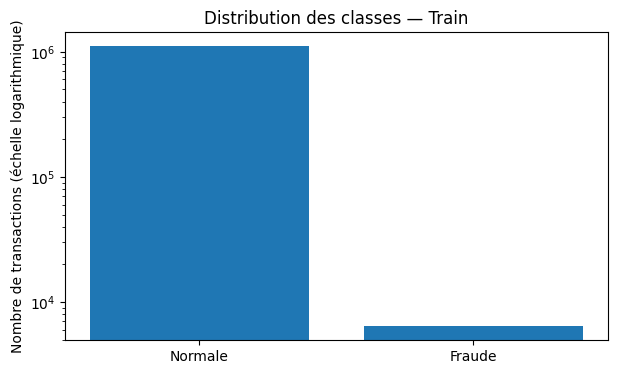

In [7]:
# Distribution des classes sur Train uniquement

class_counts = train_df["is_fraud"].value_counts().sort_index()
class_percent = train_df["is_fraud"].value_counts(
    normalize=True
).sort_index() * 100

class_distribution = pd.DataFrame({
    "Transactions": class_counts,
    "Pourcentage": class_percent
})

class_distribution.index = ["Normale", "Fraude"]

display(class_distribution.round(4))

# Visualisation
plt.figure(figsize=(7, 4))

plt.bar(
    class_distribution.index,
    class_distribution["Transactions"]
)

plt.yscale("log")
plt.ylabel("Nombre de transactions (échelle logarithmique)")
plt.title("Distribution des classes — Train")

plt.show()

In [8]:
# Statistiques des montants selon la classe

montants_stats = train_df.groupby("is_fraud")["amt"].agg(
    count="count",
    mean="mean",
    median="median",
    std="std",
    min="min",
    max="max"
)

display(montants_stats.round(2))

# Quantiles pour mieux comprendre la distribution
quantiles = train_df.groupby("is_fraud")["amt"].quantile(
    [0.25, 0.50, 0.75, 0.90, 0.99]
).unstack()

quantiles.columns = ["Q25", "Q50", "Q75", "Q90", "Q99"]

display(quantiles.round(2))

,count,mean,median,std,min,max
is_fraud,,,,,,
0,1105035,67.63,47.25,153.04,1.00,28948.90
1,6401,530.88,390.90,390.98,1.06,1371.81


,Q25,Q50,Q75,Q90,Q99
is_fraud,,,,,
0,9.61,47.25,82.51,134.24,485.75
1,244.03,390.90,901.99,1025.23,1185.32


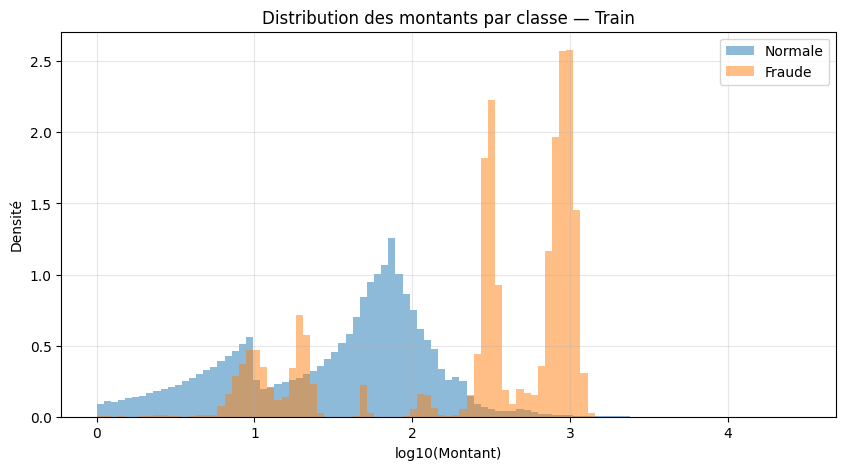

In [9]:
# Distribution des montants par classe (Train uniquement)

normal = train_df.loc[
    train_df["is_fraud"] == 0, "amt"
]

fraud = train_df.loc[
    train_df["is_fraud"] == 1, "amt"
]

# Transformation logarithmique pour la visualisation
normal_log = np.log10(normal)
fraud_log = np.log10(fraud)

plt.figure(figsize=(10, 5))

bins = np.linspace(
    min(normal_log.min(), fraud_log.min()),
    max(normal_log.max(), fraud_log.max()),
    100
)

plt.hist(
    normal_log,
    bins=bins,
    density=True,
    alpha=0.5,
    label="Normale"
)

plt.hist(
    fraud_log,
    bins=bins,
    density=True,
    alpha=0.5,
    label="Fraude"
)

plt.xlabel("log10(Montant)")
plt.ylabel("Densité")
plt.title("Distribution des montants par classe — Train")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

,total_transactions,nb_fraudes,taux_fraude
month,,,
2019-01,52525,506,0.963
2019-02,49866,517,1.037
2019-03,70939,494,0.696
2019-04,68078,376,0.552
2019-05,72532,408,0.563
2019-06,86064,354,0.411
2019-07,86596,331,0.382
2019-08,87359,382,0.437
2019-09,70652,418,0.592


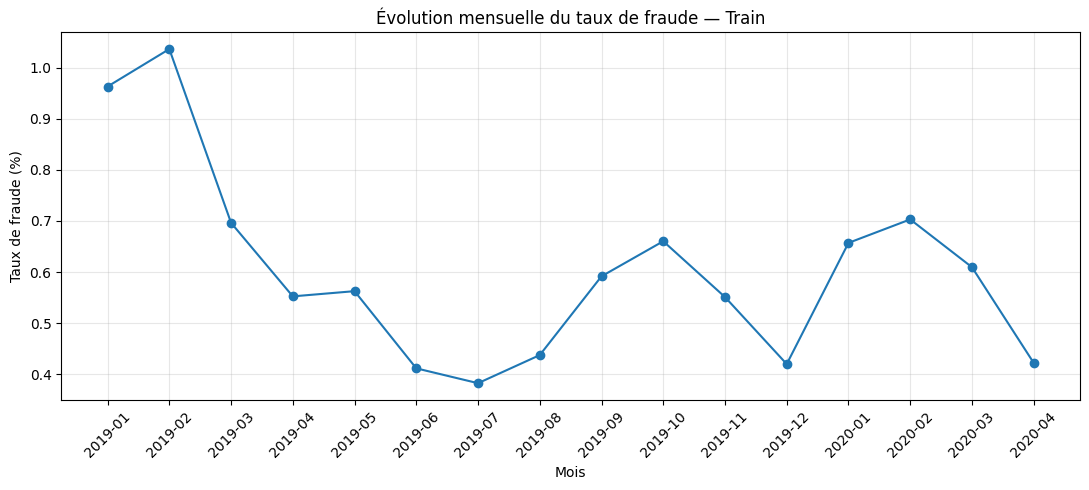

In [10]:
# Analyse mensuelle sur Train uniquement

train_eda = train_df.copy()

train_eda["month"] = (
    train_eda["trans_date_trans_time"].dt.to_period("M")
)

monthly_stats = train_eda.groupby("month").agg(
    total_transactions=("is_fraud", "size"),
    nb_fraudes=("is_fraud", "sum")
)

monthly_stats["taux_fraude"] = (
    monthly_stats["nb_fraudes"]
    / monthly_stats["total_transactions"] * 100
)

display(monthly_stats.round(3))

# Visualisation
plt.figure(figsize=(11, 5))

plt.plot(
    monthly_stats.index.astype(str),
    monthly_stats["taux_fraude"],
    marker="o"
)

plt.xlabel("Mois")
plt.ylabel("Taux de fraude (%)")
plt.title("Évolution mensuelle du taux de fraude — Train")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

,total_transactions,nb_fraudes,taux_fraude
hour,,,
0,36513,550,1.506
1,36917,570,1.544
2,36531,531,1.454
3,36661,521,1.421
4,36025,41,0.114
5,36174,49,0.135
6,36264,31,0.085
7,36142,47,0.130
8,36183,46,0.127


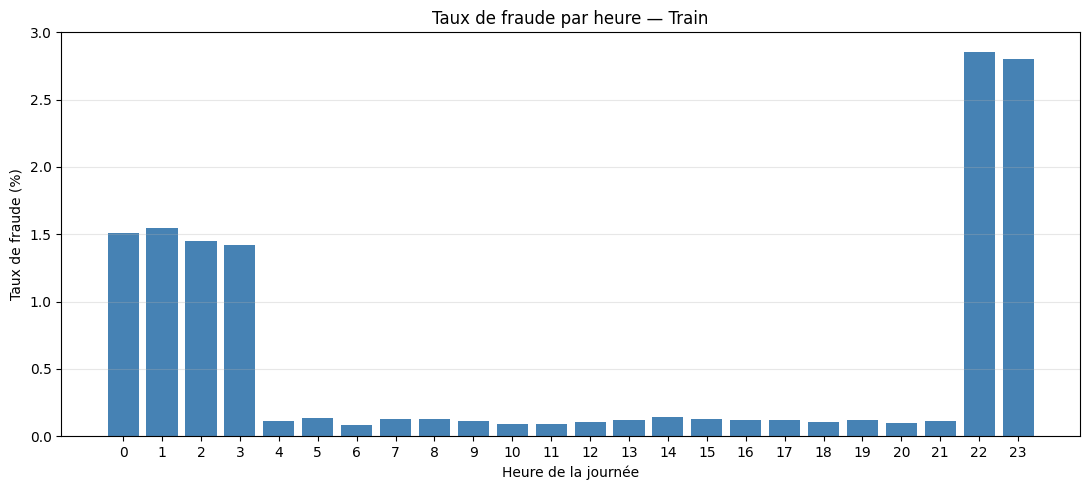

In [11]:
# Extraire l'heure de la transaction
train_eda["hour"] = (
    train_eda["trans_date_trans_time"].dt.hour
)

# Statistiques par heure
hourly_stats = train_eda.groupby("hour").agg(
    total_transactions=("is_fraud", "size"),
    nb_fraudes=("is_fraud", "sum")
)

hourly_stats["taux_fraude"] = (
    hourly_stats["nb_fraudes"]
    / hourly_stats["total_transactions"] * 100
)

display(hourly_stats.round(3))

# Visualisation
plt.figure(figsize=(11, 5))

plt.bar(
    hourly_stats.index,
    hourly_stats["taux_fraude"],
    color="steelblue"
)

plt.xlabel("Heure de la journée")
plt.ylabel("Taux de fraude (%)")
plt.title("Taux de fraude par heure — Train")
plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

,total_transactions,nb_fraudes,taux_fraude
Lundi,218831,1004,0.459
Mardi,123883,785,0.634
Mercredi,113346,709,0.626
Jeudi,127148,840,0.661
Vendredi,129800,938,0.723
Samedi,178666,1088,0.609
Dimanche,219762,1037,0.472


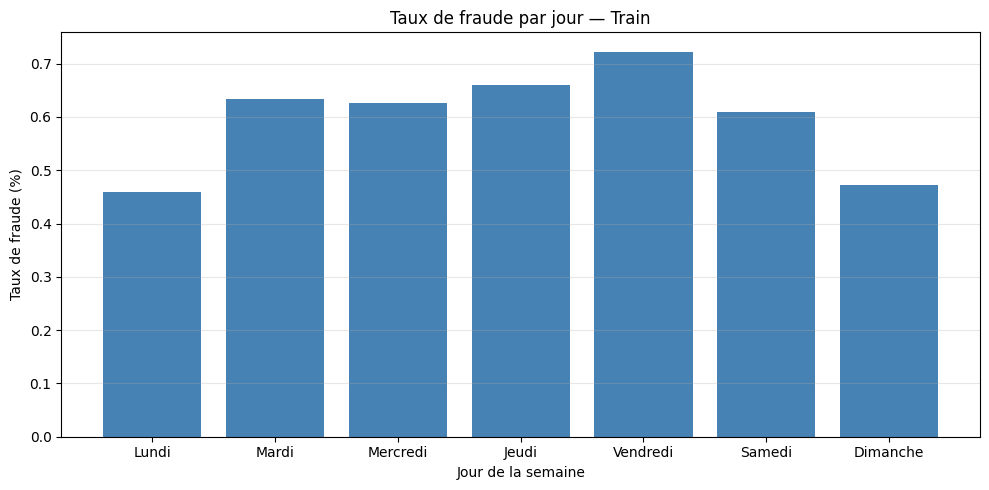

In [12]:
# Extraire le jour de la semaine
train_eda["day_of_week"] = (
    train_eda["trans_date_trans_time"].dt.dayofweek
)

# 0 = Lundi, 6 = Dimanche
days = [
    "Lundi", "Mardi", "Mercredi",
    "Jeudi", "Vendredi", "Samedi", "Dimanche"
]

# Statistiques par jour
daily_stats = train_eda.groupby("day_of_week").agg(
    total_transactions=("is_fraud", "size"),
    nb_fraudes=("is_fraud", "sum")
)

daily_stats["taux_fraude"] = (
    daily_stats["nb_fraudes"]
    / daily_stats["total_transactions"] * 100
)

daily_stats.index = days

display(daily_stats.round(3))

# Visualisation
plt.figure(figsize=(10, 5))

plt.bar(
    daily_stats.index,
    daily_stats["taux_fraude"],
    color="steelblue"
)

plt.xlabel("Jour de la semaine")
plt.ylabel("Taux de fraude (%)")
plt.title("Taux de fraude par jour — Train")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

,total_transactions,nb_fraudes,taux_fraude
category,,,
shopping_net,83578,1470,1.759
misc_net,54124,780,1.441
grocery_pos,105934,1494,1.410
shopping_pos,99823,709,0.710
gas_transport,112848,528,0.468
misc_pos,68321,210,0.307
grocery_net,38866,118,0.304
travel,34782,103,0.296
entertainment,80612,201,0.249


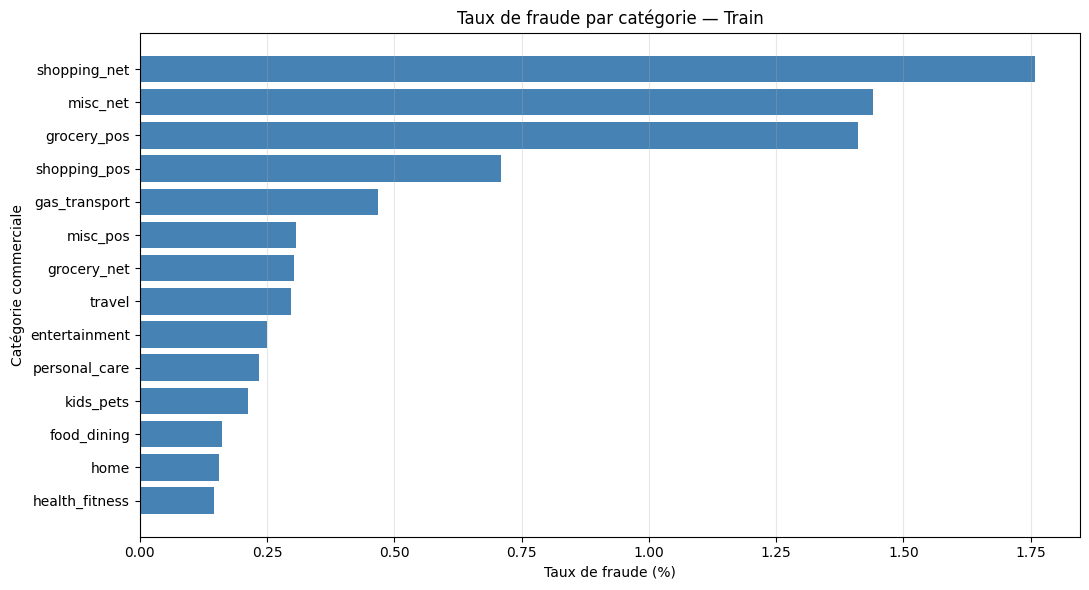

In [13]:
# Analyse des catégories commerciales — Train uniquement

category_stats = train_eda.groupby("category").agg(
    total_transactions=("is_fraud", "size"),
    nb_fraudes=("is_fraud", "sum")
)

category_stats["taux_fraude"] = (
    category_stats["nb_fraudes"]
    / category_stats["total_transactions"] * 100
)

category_stats = category_stats.sort_values(
    "taux_fraude", ascending=False
)

display(category_stats.round(3))

# Visualisation
plt.figure(figsize=(11, 6))

plt.barh(
    category_stats.index,
    category_stats["taux_fraude"],
    color="steelblue"
)

plt.xlabel("Taux de fraude (%)")
plt.ylabel("Catégorie commerciale")
plt.title("Taux de fraude par catégorie — Train")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

,total_transactions,nb_fraudes,taux_fraude
channel,,,
net,176568,2368,1.341
non_precise,660790,1620,0.245
pos,274078,2413,0.880


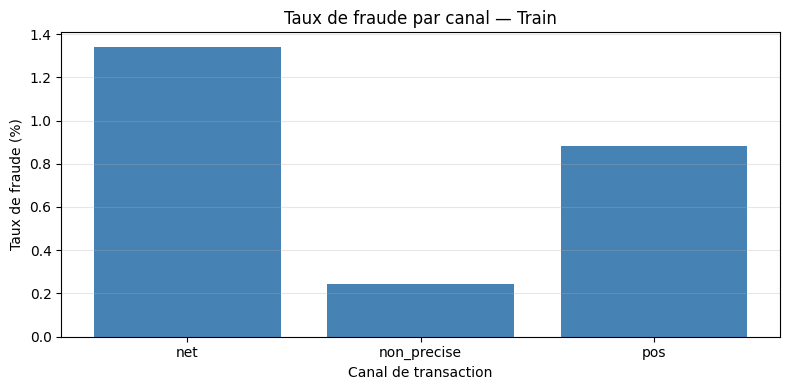

In [14]:
# Déduire le canal à partir des catégories qui le précisent

train_eda["channel"] = np.select(
    [
        train_eda["category"].str.endswith("_net"),
        train_eda["category"].str.endswith("_pos")
    ],
    ["net", "pos"],
    default="non_precise"
)

# Statistiques par canal
channel_stats = train_eda.groupby("channel").agg(
    total_transactions=("is_fraud", "size"),
    nb_fraudes=("is_fraud", "sum")
)

channel_stats["taux_fraude"] = (
    channel_stats["nb_fraudes"]
    / channel_stats["total_transactions"] * 100
)

display(channel_stats.round(3))

# Visualisation
plt.figure(figsize=(8, 4))

plt.bar(
    channel_stats.index,
    channel_stats["taux_fraude"],
    color="steelblue"
)

plt.xlabel("Canal de transaction")
plt.ylabel("Taux de fraude (%)")
plt.title("Taux de fraude par canal — Train")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
def create_time_features(data):

    data = data.copy()

    date = data["trans_date_trans_time"]

    data["hour"] = date.dt.hour
    data["day_of_week"] = date.dt.dayofweek

    data["is_weekend"] = (
        data["day_of_week"] >= 5
    ).astype(int)

    # Encodage cyclique de l'heure
    data["hour_sin"] = np.sin(
        2 * np.pi * data["hour"] / 24
    )

    data["hour_cos"] = np.cos(
        2 * np.pi * data["hour"] / 24
    )

    return data


# Appliquer la même transformation aux trois ensembles
train_fe = create_time_features(train_df)
val_fe = create_time_features(val_df)
test_fe = create_time_features(test_df)

# Vérification sur Train
display(
    train_fe[[
        "trans_date_trans_time",
        "hour",
        "day_of_week",
        "is_weekend",
        "hour_sin",
        "hour_cos"
    ]].head(10)
)

,trans_date_trans_time,hour,day_of_week,is_weekend,hour_sin,hour_cos
0,2019-01-01 00:00:18,0,1,0,0.0,1.0
1,2019-01-01 00:00:44,0,1,0,0.0,1.0
2,2019-01-01 00:00:51,0,1,0,0.0,1.0
3,2019-01-01 00:01:16,0,1,0,0.0,1.0
4,2019-01-01 00:03:06,0,1,0,0.0,1.0
5,2019-01-01 00:04:08,0,1,0,0.0,1.0
6,2019-01-01 00:04:42,0,1,0,0.0,1.0
7,2019-01-01 00:05:08,0,1,0,0.0,1.0
8,2019-01-01 00:05:18,0,1,0,0.0,1.0
9,2019-01-01 00:06:01,0,1,0,0.0,1.0


In [16]:
# Réunir temporairement les ensembles
parts = []

for name, data in [
    ("train", train_fe),
    ("val", val_fe),
    ("test", test_fe)
]:
    part = data.copy()
    part["_split"] = name
    part["_row_id"] = np.arange(len(part))
    parts.append(part)

history_df = pd.concat(parts, ignore_index=True)

# Respecter la chronologie
history_df = history_df.sort_values(
    "trans_date_trans_time",
    kind="stable"
)

# Dernière transaction connue de la même carte
history_df["previous_tx_time"] = (
    history_df.groupby("cc_num")["trans_date_trans_time"]
    .shift(1)
)

# Temps écoulé en minutes
history_df["time_since_last_tx"] = (
    history_df["trans_date_trans_time"]
    - history_df["previous_tx_time"]
).dt.total_seconds() / 60

# Indiquer la présence d'un historique
history_df["has_previous_tx"] = (
    history_df["previous_tx_time"].notna()
).astype(int)

# Séparer à nouveau les données
def recover_split(name):
    return (
        history_df[history_df["_split"] == name]
        .sort_values("_row_id")
        .drop(columns=["_split", "_row_id"])
        .reset_index(drop=True)
    )

train_fe = recover_split("train")
val_fe = recover_split("val")
test_fe = recover_split("test")

# Vérifications
print("Temps négatifs :",
      (history_df["time_since_last_tx"] < 0).sum())

print("Transactions sans historique — Train :",
      train_fe["time_since_last_tx"].isna().sum())

print("Dimensions Train :", train_fe.shape)
print("Dimensions Validation :", val_fe.shape)
print("Dimensions Test :", test_fe.shape)

Temps négatifs : 0
Transactions sans historique — Train : 970
Dimensions Train : (1111436, 30)
Dimensions Validation : (370479, 30)
Dimensions Test : (370479, 30)


In [17]:
# Choisir la première carte du Train
card_id = train_fe["cc_num"].iloc[0]

card_history = train_fe[
    train_fe["cc_num"] == card_id
].head(12)

display(card_history[[
    "trans_date_trans_time",
    "amt",
    "previous_tx_time",
    "time_since_last_tx",
    "has_previous_tx"
]])

,trans_date_trans_time,amt,previous_tx_time,time_since_last_tx,has_previous_tx
0,2019-01-01 00:00:18,4.97,NaT,NaN,0
1565,2019-01-01 16:53:34,114.79,2019-01-01 00:00:18,1013.266667,1
2299,2019-01-01 23:02:37,16.55,2019-01-01 16:53:34,369.050000,1
3606,2019-01-03 01:40:38,27.70,2019-01-01 23:02:37,1598.016667,1
4227,2019-01-03 15:24:11,43.72,2019-01-03 01:40:38,823.550000,1
5044,2019-01-04 06:18:05,196.25,2019-01-03 15:24:11,893.900000,1
5175,2019-01-04 08:59:57,77.89,2019-01-04 06:18:05,161.866667,1
5493,2019-01-04 14:19:03,9.08,2019-01-04 08:59:57,319.100000,1
5999,2019-01-04 20:55:05,94.92,2019-01-04 14:19:03,396.033333,1
6048,2019-01-04 21:33:13,33.30,2019-01-04 20:55:05,38.133333,1


In [18]:
# Compteurs des transactions précédentes sur 1h et 24h

history_df = history_df.reset_index(drop=True)

count_1h = np.zeros(len(history_df), dtype=np.int32)
count_24h = np.zeros(len(history_df), dtype=np.int32)

dates = history_df["trans_date_trans_time"].to_numpy()

# Calculer les historiques pour chaque carte
for card, indices in history_df.groupby("cc_num").indices.items():

    times = dates[indices]

    # Nombre de transactions strictement antérieures
    right = np.searchsorted(times, times, side="left")

    # Début des fenêtres temporelles
    left_1h = np.searchsorted(
        times,
        times - np.timedelta64(1, "h"),
        side="left"
    )

    left_24h = np.searchsorted(
        times,
        times - np.timedelta64(24, "h"),
        side="left"
    )

    count_1h[indices] = right - left_1h
    count_24h[indices] = right - left_24h

# Ajouter les nouvelles features
history_df["tx_count_1h"] = count_1h
history_df["tx_count_24h"] = count_24h

# Récupérer les trois ensembles
train_fe = recover_split("train")
val_fe = recover_split("val")
test_fe = recover_split("test")

print("Valeurs manquantes 1h :", train_fe["tx_count_1h"].isna().sum())
print("Valeurs manquantes 24h :", train_fe["tx_count_24h"].isna().sum())

print("Maximum 1h :", train_fe["tx_count_1h"].max())
print("Maximum 24h :", train_fe["tx_count_24h"].max())

Valeurs manquantes 1h : 0
Valeurs manquantes 24h : 0
Maximum 1h : 6
Maximum 24h : 35


In [19]:
# Sélectionner une carte
card_id = train_fe["cc_num"].iloc[0]

card_history = (
    train_fe[train_fe["cc_num"] == card_id]
    .sort_values("trans_date_trans_time")
)

display(
    card_history[[
        "trans_date_trans_time",
        "amt",
        "time_since_last_tx",
        "tx_count_1h",
        "tx_count_24h"
    ]].head(15)
)

# Vérifications de cohérence
assert (history_df["tx_count_1h"] >= 0).all()
assert (history_df["tx_count_24h"] >= 0).all()

assert (
    history_df["tx_count_1h"]
    <= history_df["tx_count_24h"]
).all()

print("Vérifications réussies.")

,trans_date_trans_time,amt,time_since_last_tx,tx_count_1h,tx_count_24h
0,2019-01-01 00:00:18,4.97,NaN,0,0
1565,2019-01-01 16:53:34,114.79,1013.266667,0,1
2299,2019-01-01 23:02:37,16.55,369.050000,0,2
3606,2019-01-03 01:40:38,27.70,1598.016667,0,0
4227,2019-01-03 15:24:11,43.72,823.550000,0,1
5044,2019-01-04 06:18:05,196.25,893.900000,0,1
5175,2019-01-04 08:59:57,77.89,161.866667,0,2
5493,2019-01-04 14:19:03,9.08,319.100000,0,3
5999,2019-01-04 20:55:05,94.92,396.033333,0,3
6048,2019-01-04 21:33:13,33.30,38.133333,1,4


Vérifications réussies.


In [20]:
# Profil de dépenses des 30 derniers jours

history_df = history_df.sort_values(
    "trans_date_trans_time", kind="stable"
).reset_index(drop=True)

dates = history_df["trans_date_trans_time"].to_numpy()
amounts = history_df["amt"].to_numpy(dtype=float)

count_30d = np.zeros(len(history_df), dtype=np.int32)
avg_30d = np.full(len(history_df), np.nan)

for card, indices in history_df.groupby("cc_num").indices.items():

    times = dates[indices]
    card_amounts = amounts[indices]

    # Début de la fenêtre de 30 jours
    left = np.searchsorted(
        times,
        times - np.timedelta64(30, "D"),
        side="left"
    )

    # Exclure la transaction actuelle et les mêmes horodatages
    right = np.searchsorted(
        times, times, side="left"
    )

    # Nombre de transactions précédentes
    counts = right - left
    count_30d[indices] = counts

    # Sommes cumulées des montants
    cumulative = np.concatenate([
        [0.0], np.cumsum(card_amounts)
    ])

    sums = cumulative[right] - cumulative[left]

    # Moyenne sur les transactions précédentes
    avg_30d[indices] = np.divide(
        sums,
        counts,
        out=np.full(len(indices), np.nan),
        where=counts > 0
    )

# Ajouter les nouvelles features
history_df["tx_count_30d"] = count_30d
history_df["avg_amount_30d"] = avg_30d

history_df["amount_ratio_30d"] = (
    history_df["amt"] / history_df["avg_amount_30d"]
)

# Séparer à nouveau Train, Validation et Test
train_fe = recover_split("train")
val_fe = recover_split("val")
test_fe = recover_split("test")

print("Moyennes manquantes :",
      train_fe["avg_amount_30d"].isna().sum())

print("Ratios manquants :",
      train_fe["amount_ratio_30d"].isna().sum())

print("Ratios infinis :",
      np.isinf(train_fe["amount_ratio_30d"]).sum())

Moyennes manquantes : 970
Ratios manquants : 970
Ratios infinis : 0


In [21]:
card_id = train_fe["cc_num"].iloc[0]

display(
    train_fe[train_fe["cc_num"] == card_id][[
        "trans_date_trans_time",
        "amt",
        "tx_count_30d",
        "avg_amount_30d",
        "amount_ratio_30d"
    ]].head(12).round(2)
)

print("Compteurs négatifs :",
      (history_df["tx_count_30d"] < 0).sum())

print("Vérification 24h <= 30j :",
      (history_df["tx_count_24h"]
       <= history_df["tx_count_30d"]).all())

,trans_date_trans_time,amt,tx_count_30d,avg_amount_30d,amount_ratio_30d
0,2019-01-01 00:00:18,4.97,0,NaN,NaN
1565,2019-01-01 16:53:34,114.79,1,4.97,23.10
2299,2019-01-01 23:02:37,16.55,2,59.88,0.28
3606,2019-01-03 01:40:38,27.70,3,45.44,0.61
4227,2019-01-03 15:24:11,43.72,4,41.00,1.07
5044,2019-01-04 06:18:05,196.25,5,41.55,4.72
5175,2019-01-04 08:59:57,77.89,6,67.33,1.16
5493,2019-01-04 14:19:03,9.08,7,68.84,0.13
5999,2019-01-04 20:55:05,94.92,8,61.37,1.55
6048,2019-01-04 21:33:13,33.30,9,65.10,0.51


Compteurs négatifs : 0
Vérification 24h <= 30j : True


In [22]:
# Audit des features historiques

h = history_df

# 1. Vérifier les dates précédentes
invalid_previous = (
    h["previous_tx_time"].notna()
    & (
        h["previous_tx_time"]
        >= h["trans_date_trans_time"]
    )
)

# 2. Vérifier les temps négatifs
negative_times = (
    h["time_since_last_tx"] < 0
).sum()

# 3. Vérifier les compteurs
negative_counts = (
    (h["tx_count_1h"] < 0)
    | (h["tx_count_24h"] < 0)
    | (h["tx_count_30d"] < 0)
).sum()

# 4. Cohérence des fenêtres
invalid_windows = (
    (h["tx_count_1h"] > h["tx_count_24h"])
    | (h["tx_count_24h"] > h["tx_count_30d"])
).sum()

# 5. Transactions simultanées pour une même carte
same_timestamp = h.duplicated(
    subset=["cc_num", "trans_date_trans_time"],
    keep=False
).sum()

print("===== AUDIT TEMPOREL =====")
print("Dates précédentes non strictement antérieures :",
      invalid_previous.sum())
print("Temps négatifs :", negative_times)
print("Compteurs négatifs :", negative_counts)
print("Fenêtres incohérentes :", invalid_windows)
print("Transactions avec horodatage identique par carte :",
      same_timestamp)

# Afficher les éventuels cas problématiques
if invalid_previous.any():
    display(
        h.loc[invalid_previous, [
            "cc_num",
            "trans_date_trans_time",
            "previous_tx_time",
            "time_since_last_tx"
        ]].head(10)
    )

===== AUDIT TEMPOREL =====
Dates précédentes non strictement antérieures : 44
Temps négatifs : 0
Compteurs négatifs : 0
Fenêtres incohérentes : 0
Transactions avec horodatage identique par carte : 88


,cc_num,trans_date_trans_time,previous_tx_time,time_since_last_tx
26758,3595192916105588,2019-01-16 05:51:27,2019-01-16 05:51:27,0.0
123026,3553629419254918,2019-03-10 02:31:27,2019-03-10 02:31:27,0.0
203801,4933461930348832,2019-04-14 16:33:06,2019-04-14 16:33:06,0.0
212408,3506042666828517,2019-04-18 17:32:31,2019-04-18 17:32:31,0.0
360795,374930071163758,2019-06-16 23:58:35,2019-06-16 23:58:35,0.0
392321,375082648741747,2019-06-28 21:25:50,2019-06-28 21:25:50,0.0
503889,6538441737335434,2019-08-06 18:17:56,2019-08-06 18:17:56,0.0
517643,180036456789979,2019-08-11 19:26:21,2019-08-11 19:26:21,0.0
561465,581686439828,2019-08-26 21:47:51,2019-08-26 21:47:51,0.0
627658,6011504998544485,2019-09-23 16:43:49,2019-09-23 16:43:49,0.0


In [23]:
import numpy as np

# Calcul de la distance géographique
def haversine_distance(lat1, lon1, lat2, lon2):

    R = 6371  # Rayon moyen de la Terre en km

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2)**2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2)**2
    )

    a = np.clip(a, 0, 1)

    c = 2 * np.arcsin(np.sqrt(a))

    return R * c


# Appliquer la même transformation aux trois ensembles
for data in [train_fe, val_fe, test_fe]:

    data["distance_km"] = haversine_distance(
        data["lat"],
        data["long"],
        data["merch_lat"],
        data["merch_long"]
    )

# Vérification sur Train
display(
    train_fe[[
        "amt",
        "lat",
        "long",
        "merch_lat",
        "merch_long",
        "distance_km"
    ]].head(10).round(2)
)

print("\nStatistiques géographiques :")
print(train_fe["distance_km"].describe().round(2))

print("\nDistances manquantes :",
      train_fe["distance_km"].isna().sum())

print("Distances négatives :",
      (train_fe["distance_km"] < 0).sum())

,amt,lat,long,merch_lat,merch_long,distance_km
0,4.97,36.08,-81.18,36.01,-82.05,78.60
1,107.23,48.89,-118.21,49.16,-118.19,30.21
2,220.11,42.18,-112.26,43.15,-112.15,108.21
3,45.00,46.23,-112.11,47.03,-112.56,95.67
4,41.96,38.42,-79.46,38.67,-78.63,77.56
5,94.63,40.38,-75.20,40.65,-76.15,85.92
6,44.54,37.99,-100.99,37.16,-100.15,118.12
7,71.65,38.84,-78.60,38.95,-78.54,12.77
8,4.27,40.34,-79.66,40.35,-79.96,25.27
9,198.39,36.52,-87.35,37.18,-87.49,74.08



Statistiques géographiques :
count    1111436.00
mean          76.10
std           29.11
min            0.02
25%           55.33
50%           78.21
75%           98.49
max          152.12
Name: distance_km, dtype: float64

Distances manquantes : 0
Distances négatives : 0


In [24]:
# Audit des features historiques

h = history_df

# 1. Vérifier les dates précédentes
invalid_previous = (
    h["previous_tx_time"].notna()
    & (
        h["previous_tx_time"]
        >= h["trans_date_trans_time"]
    )
)

# 2. Vérifier les temps négatifs
negative_times = (
    h["time_since_last_tx"] < 0
).sum()

# 3. Vérifier les compteurs
negative_counts = (
    (h["tx_count_1h"] < 0)
    | (h["tx_count_24h"] < 0)
    | (h["tx_count_30d"] < 0)
).sum()

# 4. Cohérence des fenêtres
invalid_windows = (
    (h["tx_count_1h"] > h["tx_count_24h"])
    | (h["tx_count_24h"] > h["tx_count_30d"])
).sum()

# 5. Transactions simultanées pour une même carte
same_timestamp = h.duplicated(
    subset=["cc_num", "trans_date_trans_time"],
    keep=False
).sum()

print("===== AUDIT TEMPOREL =====")
print("Dates précédentes non strictement antérieures :",
      invalid_previous.sum())
print("Temps négatifs :", negative_times)
print("Compteurs négatifs :", negative_counts)
print("Fenêtres incohérentes :", invalid_windows)
print("Transactions avec horodatage identique par carte :",
      same_timestamp)

# Afficher les éventuels cas problématiques
if invalid_previous.any():
    display(
        h.loc[invalid_previous, [
            "cc_num",
            "trans_date_trans_time",
            "previous_tx_time",
            "time_since_last_tx"
        ]].head(10)
    )

===== AUDIT TEMPOREL =====
Dates précédentes non strictement antérieures : 44
Temps négatifs : 0
Compteurs négatifs : 0
Fenêtres incohérentes : 0
Transactions avec horodatage identique par carte : 88


,cc_num,trans_date_trans_time,previous_tx_time,time_since_last_tx
26758,3595192916105588,2019-01-16 05:51:27,2019-01-16 05:51:27,0.0
123026,3553629419254918,2019-03-10 02:31:27,2019-03-10 02:31:27,0.0
203801,4933461930348832,2019-04-14 16:33:06,2019-04-14 16:33:06,0.0
212408,3506042666828517,2019-04-18 17:32:31,2019-04-18 17:32:31,0.0
360795,374930071163758,2019-06-16 23:58:35,2019-06-16 23:58:35,0.0
392321,375082648741747,2019-06-28 21:25:50,2019-06-28 21:25:50,0.0
503889,6538441737335434,2019-08-06 18:17:56,2019-08-06 18:17:56,0.0
517643,180036456789979,2019-08-11 19:26:21,2019-08-11 19:26:21,0.0
561465,581686439828,2019-08-26 21:47:51,2019-08-26 21:47:51,0.0
627658,6011504998544485,2019-09-23 16:43:49,2019-09-23 16:43:49,0.0


In [25]:
# Corriger les historiques avec horodatages identiques

# Une seule occurrence pour chaque couple carte/date
unique_times = (
    history_df[["cc_num", "trans_date_trans_time"]]
    .drop_duplicates()
    .sort_values(["cc_num", "trans_date_trans_time"])
    .copy()
)

# Dernière date strictement antérieure par carte
unique_times["previous_tx_time"] = (
    unique_times.groupby("cc_num")["trans_date_trans_time"]
    .shift(1)
)

# Retirer les anciennes features incorrectes
history_df = history_df.drop(
    columns=[
        "previous_tx_time",
        "time_since_last_tx",
        "has_previous_tx"
    ],
    errors="ignore"
)

# Associer la dernière date connue à chaque transaction
history_df = history_df.merge(
    unique_times,
    on=["cc_num", "trans_date_trans_time"],
    how="left",
    sort=False,
    validate="many_to_one"
)

# Recalculer le délai en minutes
history_df["time_since_last_tx"] = (
    history_df["trans_date_trans_time"]
    - history_df["previous_tx_time"]
).dt.total_seconds() / 60

history_df["has_previous_tx"] = (
    history_df["previous_tx_time"].notna()
).astype(int)

# Actualiser les trois ensembles
train_fe = recover_split("train")
val_fe = recover_split("val")
test_fe = recover_split("test")

In [26]:
# Vérifier les dates précédentes
invalid_previous = (
    history_df["previous_tx_time"].notna()
    & (
        history_df["previous_tx_time"]
        >= history_df["trans_date_trans_time"]
    )
)

print("Dates précédentes invalides :", invalid_previous.sum())

print("Temps négatifs :",
      (history_df["time_since_last_tx"] < 0).sum())

print("Nombre de transactions :",
      len(history_df))

# Vérification automatique
assert invalid_previous.sum() == 0
assert (history_df["time_since_last_tx"].dropna() > 0).all()
assert len(history_df) == 1852394

print("\nAudit des dates précédentes : OK")

# Examiner quelques transactions simultanées
same_time = history_df.duplicated(
    ["cc_num", "trans_date_trans_time"],
    keep=False
)

display(
    history_df.loc[same_time, [
        "cc_num",
        "trans_date_trans_time",
        "previous_tx_time",
        "time_since_last_tx"
    ]].head(10)
)

Dates précédentes invalides : 0
Temps négatifs : 0
Nombre de transactions : 1852394

Audit des dates précédentes : OK


,cc_num,trans_date_trans_time,previous_tx_time,time_since_last_tx
26757,3595192916105588,2019-01-16 05:51:27,2019-01-15 23:23:32,387.916667
26758,3595192916105588,2019-01-16 05:51:27,2019-01-15 23:23:32,387.916667
123025,3553629419254918,2019-03-10 02:31:27,2019-03-09 23:44:41,166.766667
123026,3553629419254918,2019-03-10 02:31:27,2019-03-09 23:44:41,166.766667
203800,4933461930348832,2019-04-14 16:33:06,2019-04-14 12:41:52,231.233333
203801,4933461930348832,2019-04-14 16:33:06,2019-04-14 12:41:52,231.233333
212407,3506042666828517,2019-04-18 17:32:31,2019-04-18 01:33:47,958.733333
212408,3506042666828517,2019-04-18 17:32:31,2019-04-18 01:33:47,958.733333
360794,374930071163758,2019-06-16 23:58:35,2019-06-16 20:46:00,192.583333
360795,374930071163758,2019-06-16 23:58:35,2019-06-16 20:46:00,192.583333


In [27]:
# Test de causalité temporelle sur des transactions échantillonnées

# Sélectionner des transactions dans chaque ensemble
sample_indices = []

for split in ["train", "val", "test"]:
    ids = history_df.index[
        history_df["_split"] == split
    ]

    selected = pd.Series(ids).sample(
        n=10, random_state=42
    )

    sample_indices.extend(selected.tolist())

# Ajouter des transactions avec horodatages identiques
same_time = history_df.duplicated(
    ["cc_num", "trans_date_trans_time"],
    keep=False
)

sample_indices.extend(
    history_df.index[same_time][:10].tolist()
)

# Ajouter des premières transactions sans historique
sample_indices.extend(
    history_df.index[
        history_df["has_previous_tx"] == 0
    ][:5].tolist()
)

sample_indices = list(dict.fromkeys(sample_indices))

# Accès aux transactions de chaque carte
card_groups = history_df.groupby("cc_num")

errors = []

for idx in sample_indices:

    row = history_df.loc[idx]

    card_history = card_groups.get_group(row["cc_num"])
    t = row["trans_date_trans_time"]

    # Historique strictement antérieur
    past = card_history[
        card_history["trans_date_trans_time"] < t
    ]

    # Fenêtres temporelles
    past_1h = past[
        past["trans_date_trans_time"] >= t - pd.Timedelta(hours=1)
    ]

    past_24h = past[
        past["trans_date_trans_time"] >= t - pd.Timedelta(hours=24)
    ]

    past_30d = past[
        past["trans_date_trans_time"] >= t - pd.Timedelta(days=30)
    ]

    # Valeurs recalculées indépendamment
    previous_time = past["trans_date_trans_time"].max()

    time_diff = (
        (t - previous_time).total_seconds() / 60
        if pd.notna(previous_time) else np.nan
    )

    avg_amount = (
        past_30d["amt"].mean()
        if len(past_30d) > 0 else np.nan
    )

    ratio = (
        row["amt"] / avg_amount
        if pd.notna(avg_amount) and avg_amount > 0
        else np.nan
    )

    expected = {
        "has_previous_tx": int(len(past) > 0),
        "time_since_last_tx": time_diff,
        "tx_count_1h": len(past_1h),
        "tx_count_24h": len(past_24h),
        "tx_count_30d": len(past_30d),
        "avg_amount_30d": avg_amount,
        "amount_ratio_30d": ratio
    }

    # Comparaison avec les features déjà calculées
    for feature, value in expected.items():

        if not np.isclose(
            row[feature], value,
            rtol=1e-8,
            atol=1e-6,
            equal_nan=True
        ):
            errors.append((idx, feature, row[feature], value))

print("===== TEST DE CAUSALITÉ TEMPORELLE =====")
print("Transactions vérifiées :", len(sample_indices))
print("Incohérences détectées :", len(errors))

if errors:
    display(pd.DataFrame(
        errors,
        columns=["Index", "Feature", "Calcul initial", "Calcul indépendant"]
    ).head(20))
else:
    print("Toutes les features vérifiées sont cohérentes.")

===== TEST DE CAUSALITÉ TEMPORELLE =====
Transactions vérifiées : 45
Incohérences détectées : 0
Toutes les features vérifiées sont cohérentes.


In [28]:
# Ajouter la distance géographique au dataset historique

history_df["distance_km"] = haversine_distance(
    history_df["lat"],
    history_df["long"],
    history_df["merch_lat"],
    history_df["merch_long"]
)

# Reconstruire les ensembles avec toutes les features
train_fe = recover_split("train")
val_fe = recover_split("val")
test_fe = recover_split("test")

# Vérification
for name, data in [
    ("Train", train_fe),
    ("Validation", val_fe),
    ("Test", test_fe)
]:
    print(name, "- distance_km présente :",
          "distance_km" in data.columns)

print("\nValeurs manquantes distance :",
      train_fe["distance_km"].isna().sum())

Train - distance_km présente : True
Validation - distance_km présente : True
Test - distance_km présente : True

Valeurs manquantes distance : 0


In [29]:
numeric_features = [
    "amt",
    "city_pop",
    "hour_sin",
    "hour_cos",
    "day_of_week",
    "is_weekend",
    "time_since_last_tx",
    "has_previous_tx",
    "tx_count_1h",
    "tx_count_24h",
    "tx_count_30d",
    "avg_amount_30d",
    "amount_ratio_30d",
    "distance_km"
]

categorical_features = ["category"]

features = numeric_features + categorical_features

# Features
X_train = train_fe[features].copy()
X_val = val_fe[features].copy()
X_test = test_fe[features].copy()

# Cible
y_train = train_fe["is_fraud"].copy()
y_val = val_fe["is_fraud"].copy()
y_test = test_fe["is_fraud"].copy()

print("Train :", X_train.shape)
print("Validation :", X_val.shape)
print("Test :", X_test.shape)

print("\nTypes des variables :")
print(X_train.dtypes.value_counts())

print("\nValeurs manquantes :")
print(X_train.isna().sum())

print("\nNombre de catégories :")
print(X_train["category"].nunique())

assert "is_fraud" not in X_train.columns
assert list(X_train.columns) == list(X_val.columns)
assert list(X_train.columns) == list(X_test.columns)

Train : (1111436, 15)
Validation : (370479, 15)
Test : (370479, 15)

Types des variables :
float64    7
int32      4
int64      3
object     1
Name: count, dtype: int64

Valeurs manquantes :
amt                     0
city_pop                0
hour_sin                0
hour_cos                0
day_of_week             0
is_weekend              0
time_since_last_tx    970
has_previous_tx         0
tx_count_1h             0
tx_count_24h            0
tx_count_30d            0
avg_amount_30d        970
amount_ratio_30d      970
distance_km             0
category                0
dtype: int64

Nombre de catégories :
14


In [30]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Prétraitement numérique pour Logistic Regression
numeric_transformer_lr = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Prétraitement numérique pour XGBoost
numeric_transformer_xgb = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Prétraitement catégoriel
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Pipeline pour Logistic Regression
preprocessor_lr = ColumnTransformer([
    ("num", numeric_transformer_lr, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Pipeline pour XGBoost
preprocessor_xgb = ColumnTransformer([
    ("num", numeric_transformer_xgb, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Préprocesseur Logistic Regression créé.")
print("Préprocesseur XGBoost créé.")

Préprocesseur Logistic Regression créé.
Préprocesseur XGBoost créé.


In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import average_precision_score, roc_auc_score
import pandas as pd

# Logistic Regression sans pondération
lr_normal = Pipeline([
    ("preprocessing", clone(preprocessor_lr)),
    ("model", LogisticRegression(
        class_weight=None,
        max_iter=1500,
        random_state=42
    ))
])

# Logistic Regression avec pondération
lr_balanced = Pipeline([
    ("preprocessing", clone(preprocessor_lr)),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1500,
        random_state=42
    ))
])

# Entraînement
lr_normal.fit(X_train, y_train)
lr_balanced.fit(X_train, y_train)

# Scores sur Validation
scores_normal = lr_normal.predict_proba(X_val)[:, 1]
scores_balanced = lr_balanced.predict_proba(X_val)[:, 1]

# Comparaison
results_lr = pd.DataFrame({
    "Modele": [
        "Logistic normale",
        "Logistic balanced"
    ],
    "PR_AUC": [
        average_precision_score(y_val, scores_normal),
        average_precision_score(y_val, scores_balanced)
    ],
    "ROC_AUC": [
        roc_auc_score(y_val, scores_normal),
        roc_auc_score(y_val, scores_balanced)
    ]
})

display(results_lr.round(4))

,Modele,PR_AUC,ROC_AUC
0,Logistic normale,0.4139,0.9239
1,Logistic balanced,0.2547,0.9621


In [32]:
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.preprocessing import OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score

# Prétraitement avant SMOTENC
pre_smote = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1
        ))
    ]), categorical_features)
])

# Position de la variable catégorielle
cat_index = len(numeric_features)

# Encodage après SMOTENC
post_smote = ColumnTransformer([
    ("num", "passthrough", list(range(cat_index))),
    ("cat", OneHotEncoder(handle_unknown="ignore"), [cat_index])
])

# Pipeline complet
lr_smote = ImbPipeline([
    ("pre_smote", pre_smote),

    ("smote", SMOTENC(
        categorical_features=[cat_index],
        sampling_strategy=0.02,
        random_state=42,
        k_neighbors=5
    )),

    ("post_smote", post_smote),

    ("model", LogisticRegression(
        class_weight=None,
        max_iter=1500,
        random_state=42
    ))
])

# Entraînement uniquement sur Train
lr_smote.fit(X_train, y_train)

# Évaluation sur Validation
scores_smote = lr_smote.predict_proba(X_val)[:, 1]

print("===== Logistic Regression + SMOTENC =====")

print("PR-AUC :", round(
    average_precision_score(y_val, scores_smote), 4
))

print("ROC-AUC :", round(
    roc_auc_score(y_val, scores_smote), 4
))

===== Logistic Regression + SMOTENC =====
PR-AUC : 0.3881
ROC-AUC : 0.936


In [33]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    fbeta_score,
    matthews_corrcoef
)

# Scores des trois modèles
logistic_models = {
    "Logistic normale": scores_normal,
    "Logistic balanced": scores_balanced,
    "Logistic + SMOTENC": scores_smote
}

# Données de validation
y_true = y_val.to_numpy()
amounts = val_fe["amt"].to_numpy()

COST_PER_ALERT = 5

# Seuils à tester
thresholds = np.linspace(0, 1, 201)

results_cost = []

# Coût sans système de détection
cost_without_model = amounts[y_true == 1].sum()

for name, scores in logistic_models.items():

    best_cost = float("inf")
    best_threshold = None

    # Recherche du meilleur seuil
    for threshold in thresholds:

        y_pred = (scores >= threshold).astype(int)

        missed = (y_true == 1) & (y_pred == 0)

        missed_cost = amounts[missed].sum()
        alert_cost = y_pred.sum() * COST_PER_ALERT

        total_cost = missed_cost + alert_cost

        if total_cost < best_cost:
            best_cost = total_cost
            best_threshold = threshold

    # Évaluation au meilleur seuil
    y_pred = (scores >= best_threshold).astype(int)

    tp = ((y_true == 1) & (y_pred == 1)).sum()
    fp = ((y_true == 0) & (y_pred == 1)).sum()
    fn = ((y_true == 1) & (y_pred == 0)).sum()

    results_cost.append({
        "Modele": name,
        "Threshold": best_threshold,
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F2": fbeta_score(
            y_true, y_pred, beta=2, zero_division=0
        ),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "FP": fp,
        "FN": fn,
        "Alertes": y_pred.sum(),
        "Total_Cost": best_cost
    })

logistic_cost_df = pd.DataFrame(results_cost)

print("Coût sans modèle :", round(cost_without_model, 2))

display(
    logistic_cost_df.sort_values(
        "Total_Cost"
    ).round(4)
)

Coût sans modèle : 989313.46


,Modele,Threshold,Precision,Recall,F2,MCC,FP,FN,Alertes,Total_Cost
1,Logistic balanced,0.775,0.1745,0.7759,0.4593,0.3622,6978,426,8453,87160.85
2,Logistic + SMOTENC,0.050,0.1025,0.7501,0.3313,0.2692,12489,475,13915,169318.57
0,Logistic normale,0.015,0.0827,0.7259,0.2841,0.2358,15307,521,16687,227505.49


In [34]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import average_precision_score, roc_auc_score

# Premier modèle Random Forest
rf_model = Pipeline([
    ("preprocessing", clone(preprocessor_xgb)),

    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=14,
        min_samples_leaf=10,
        max_samples=0.5,
        bootstrap=True,
        class_weight=None,
        random_state=42,
        n_jobs=-1
    ))
])

# Entraînement
rf_model.fit(X_train, y_train)

# Scores sur Validation
scores_rf = rf_model.predict_proba(X_val)[:, 1]

print("===== Random Forest =====")

print("PR-AUC :", round(
    average_precision_score(y_val, scores_rf), 4
))

print("ROC-AUC :", round(
    roc_auc_score(y_val, scores_rf), 4
))

===== Random Forest =====
PR-AUC : 0.8552
ROC-AUC : 0.9916


In [35]:
from sklearn.base import clone
from sklearn.metrics import average_precision_score, roc_auc_score

# Copier le modèle initial
rf_balanced = clone(rf_model)

# Activer la pondération des classes
rf_balanced.set_params(
    model__class_weight="balanced_subsample"
)

# Entraînement
rf_balanced.fit(X_train, y_train)

# Scores sur Validation
scores_rf_balanced = rf_balanced.predict_proba(X_val)[:, 1]

# Comparaison
results_rf = pd.DataFrame({
    "Modele": [
        "Random Forest initial",
        "Random Forest balanced"
    ],
    "PR_AUC": [
        average_precision_score(y_val, scores_rf),
        average_precision_score(y_val, scores_rf_balanced)
    ],
    "ROC_AUC": [
        roc_auc_score(y_val, scores_rf),
        roc_auc_score(y_val, scores_rf_balanced)
    ]
})

display(results_rf.round(4))

,Modele,PR_AUC,ROC_AUC
0,Random Forest initial,0.8552,0.9916
1,Random Forest balanced,0.8343,0.9939


In [36]:
from sklearn.base import clone
from sklearn.metrics import average_precision_score, roc_auc_score

# Reprendre le pipeline SMOTENC
rf_smote = clone(lr_smote)

# Remplacer Logistic Regression par Random Forest
rf_smote.set_params(
    model=clone(rf_model.named_steps["model"])
)

# Entraîner uniquement sur Train
rf_smote.fit(X_train, y_train)

# Prédictions sur Validation
scores_rf_smote = rf_smote.predict_proba(X_val)[:, 1]

print("===== Random Forest + SMOTENC =====")

print("PR-AUC :", round(
    average_precision_score(y_val, scores_rf_smote), 4
))

print("ROC-AUC :", round(
    roc_auc_score(y_val, scores_rf_smote), 4
))

===== Random Forest + SMOTENC =====
PR-AUC : 0.8546
ROC-AUC : 0.9913


In [40]:
results_rf = pd.DataFrame({
    "Modele": [
        "Random Forest initial",
        "Random Forest balanced",
        "Random Forest + SMOTENC"
    ],
    "PR_AUC": [
        average_precision_score(y_val, scores_rf),
        average_precision_score(y_val, scores_rf_balanced),
        average_precision_score(y_val, scores_rf_smote)
    ],
    "ROC_AUC": [
        roc_auc_score(y_val, scores_rf),
        roc_auc_score(y_val, scores_rf_balanced),
        roc_auc_score(y_val, scores_rf_smote)
    ]
})

display(results_rf.sort_values(
    "PR_AUC", ascending=False
).round(4))

,Modele,PR_AUC,ROC_AUC
0,Random Forest initial,0.8552,0.9916
2,Random Forest + SMOTENC,0.8546,0.9913
1,Random Forest balanced,0.8343,0.9939


In [41]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import average_precision_score, roc_auc_score

# XGBoost initial sans rééquilibrage
xgb_initial = Pipeline([
    ("preprocessing", clone(preprocessor_xgb)),

    ("model", XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=5,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    ))
])

# Entraînement uniquement sur Train
xgb_initial.fit(X_train, y_train)

# Scores sur Validation
scores_xgb_initial = xgb_initial.predict_proba(X_val)[:, 1]

print("===== XGBoost initial =====")

print("PR-AUC :", round(
    average_precision_score(y_val, scores_xgb_initial), 4
))

print("ROC-AUC :", round(
    roc_auc_score(y_val, scores_xgb_initial), 4
))

===== XGBoost initial =====
PR-AUC : 0.9087
ROC-AUC : 0.9979


In [42]:
from sklearn.base import clone
from sklearn.metrics import average_precision_score, roc_auc_score

# Calculer le rapport des classes sur Train
n_normal = (y_train == 0).sum()
n_fraud = (y_train == 1).sum()

scale_weight = n_normal / n_fraud

print("scale_pos_weight :", round(scale_weight, 2))

# Créer une version pondérée du XGBoost initial
xgb_weighted = clone(xgb_initial)

xgb_weighted.set_params(
    model__scale_pos_weight=scale_weight
)

# Entraînement
xgb_weighted.fit(X_train, y_train)

# Scores sur Validation
scores_xgb_weighted = xgb_weighted.predict_proba(X_val)[:, 1]

# Comparaison
results_xgb = pd.DataFrame({
    "Modele": [
        "XGBoost initial",
        "XGBoost weighted"
    ],
    "PR_AUC": [
        average_precision_score(y_val, scores_xgb_initial),
        average_precision_score(y_val, scores_xgb_weighted)
    ],
    "ROC_AUC": [
        roc_auc_score(y_val, scores_xgb_initial),
        roc_auc_score(y_val, scores_xgb_weighted)
    ]
})

display(results_xgb.round(4))

scale_pos_weight : 172.63


,Modele,PR_AUC,ROC_AUC
0,XGBoost initial,0.9087,0.9979
1,XGBoost weighted,0.8963,0.9983


In [43]:
from sklearn.base import clone
from sklearn.metrics import average_precision_score, roc_auc_score

# Reprendre le pipeline contenant SMOTENC
xgb_smote = clone(lr_smote)

# Remplacer Logistic Regression par XGBoost sans pondération
xgb_smote.set_params(
    model=clone(xgb_initial.named_steps["model"])
)

# Entraînement uniquement sur Train
xgb_smote.fit(X_train, y_train)

# Prédictions sur Validation
scores_xgb_smote = xgb_smote.predict_proba(X_val)[:, 1]

print("===== XGBoost + SMOTENC =====")

print("PR-AUC :", round(
    average_precision_score(y_val, scores_xgb_smote), 4
))

print("ROC-AUC :", round(
    roc_auc_score(y_val, scores_xgb_smote), 4
))

===== XGBoost + SMOTENC =====
PR-AUC : 0.8996
ROC-AUC : 0.9967


In [44]:
results_xgb = pd.DataFrame({
    "Modele": [
        "XGBoost initial",
        "XGBoost weighted",
        "XGBoost + SMOTENC"
    ],
    "PR_AUC": [
        average_precision_score(y_val, scores_xgb_initial),
        average_precision_score(y_val, scores_xgb_weighted),
        average_precision_score(y_val, scores_xgb_smote)
    ],
    "ROC_AUC": [
        roc_auc_score(y_val, scores_xgb_initial),
        roc_auc_score(y_val, scores_xgb_weighted),
        roc_auc_score(y_val, scores_xgb_smote)
    ]
})

display(
    results_xgb.sort_values(
        "PR_AUC", ascending=False
    ).round(4)
)

,Modele,PR_AUC,ROC_AUC
0,XGBoost initial,0.9087,0.9979
2,XGBoost + SMOTENC,0.8996,0.9967
1,XGBoost weighted,0.8963,0.9983


In [45]:
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.base import clone
from sklearn.metrics import average_precision_score, roc_auc_score

# Vérifier l'ordre chronologique
assert train_fe["trans_date_trans_time"].is_monotonic_increasing

# Validation croisée chronologique
tscv = TimeSeriesSplit(n_splits=3)

# Espace de recherche
param_dist = {
    "model__n_estimators": [150, 250, 350, 450],
    "model__max_depth": [4, 6, 8],
    "model__learning_rate": [0.03, 0.05, 0.08],
    "model__min_child_weight": [1, 5, 10],
    "model__subsample": [0.8, 1.0],
    "model__colsample_bytree": [0.8, 1.0],
    "model__reg_lambda": [1, 5, 10]
}

# Recherche des hyperparamètres
search_xgb = RandomizedSearchCV(
    estimator=clone(xgb_initial),
    param_distributions=param_dist,
    n_iter=12,
    scoring="average_precision",
    cv=tscv,
    random_state=42,
    n_jobs=1,
    verbose=2,
    refit=True
)

# Optimisation sur Train uniquement
search_xgb.fit(X_train, y_train)

print("Meilleurs hyperparamètres :")
print(search_xgb.best_params_)

print("\nMeilleure PR-AUC moyenne en CV :")
print(round(search_xgb.best_score_, 4))

Fitting 3 folds for each of 12 candidates, totalling 36 fits
[CV] END model__colsample_bytree=1.0, model__learning_rate=0.08, model__max_depth=4, model__min_child_weight=5, model__n_estimators=450, model__reg_lambda=10, model__subsample=0.8; total time=   6.5s
[CV] END model__colsample_bytree=1.0, model__learning_rate=0.08, model__max_depth=4, model__min_child_weight=5, model__n_estimators=450, model__reg_lambda=10, model__subsample=0.8; total time=  12.0s
[CV] END model__colsample_bytree=1.0, model__learning_rate=0.08, model__max_depth=4, model__min_child_weight=5, model__n_estimators=450, model__reg_lambda=10, model__subsample=0.8; total time=  17.1s
[CV] END model__colsample_bytree=1.0, model__learning_rate=0.03, model__max_depth=8, model__min_child_weight=10, model__n_estimators=450, model__reg_lambda=5, model__subsample=0.8; total time=   8.5s
[CV] END model__colsample_bytree=1.0, model__learning_rate=0.03, model__max_depth=8, model__min_child_weight=10, model__n_estimators=450, m

In [46]:
# Résultats complets de la recherche
cv_results = pd.DataFrame(search_xgb.cv_results_)

columns = [
    "param_model__n_estimators",
    "param_model__max_depth",
    "param_model__learning_rate",
    "param_model__min_child_weight",
    "param_model__subsample",
    "param_model__colsample_bytree",
    "param_model__reg_lambda",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]

display(
    cv_results[columns]
    .sort_values("rank_test_score")
    .round(4)
)

,param_model__n_estimators,param_model__max_depth,param_model__learning_rate,param_model__min_child_weight,param_model__subsample,param_model__colsample_bytree,param_model__reg_lambda,mean_test_score,std_test_score,rank_test_score
5,350,8,0.05,5,0.8,1.0,1,0.9125,0.0265,1
9,450,6,0.05,5,0.8,0.8,1,0.9123,0.0262,2
8,350,8,0.08,1,0.8,1.0,5,0.9107,0.0284,3
1,450,8,0.03,10,0.8,1.0,5,0.9102,0.0285,4
2,450,8,0.08,10,0.8,1.0,10,0.9093,0.0301,5
0,450,4,0.08,5,0.8,1.0,10,0.9072,0.0279,6
10,350,6,0.03,1,1.0,0.8,5,0.9061,0.0233,7
11,450,4,0.08,5,1.0,1.0,1,0.9054,0.0278,8
4,350,4,0.08,1,1.0,1.0,5,0.9023,0.0272,9
7,250,4,0.08,5,0.8,0.8,10,0.8978,0.0246,10


In [47]:
# Meilleur modèle issu de RandomizedSearchCV
best_xgb = search_xgb.best_estimator_

# Prédictions sur Validation
scores_xgb_best = best_xgb.predict_proba(X_val)[:, 1]

comparison_xgb = pd.DataFrame({
    "Modele": [
        "XGBoost initial",
        "XGBoost optimisé"
    ],
    "PR_AUC": [
        average_precision_score(y_val, scores_xgb_initial),
        average_precision_score(y_val, scores_xgb_best)
    ],
    "ROC_AUC": [
        roc_auc_score(y_val, scores_xgb_initial),
        roc_auc_score(y_val, scores_xgb_best)
    ]
})

display(comparison_xgb.round(4))

,Modele,PR_AUC,ROC_AUC
0,XGBoost initial,0.9087,0.9979
1,XGBoost optimisé,0.9175,0.9984


In [48]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    fbeta_score,
    matthews_corrcoef,
    average_precision_score
)

# Scores sur Validation
models_scores = {
    "XGBoost initial": scores_xgb_initial,
    "XGBoost optimisé": scores_xgb_best
}

y_true = y_val.to_numpy()
amounts = val_fe["amt"].to_numpy()

COST_PER_ALERT = 5

# Grille de seuils
thresholds = np.linspace(0, 1, 401)

results = []

for name, scores in models_scores.items():

    best_cost = float("inf")
    best_threshold = None

    for threshold in thresholds:

        alerts = scores >= threshold

        missed = (y_true == 1) & (~alerts)

        missed_cost = amounts[missed].sum()
        alert_cost = alerts.sum() * COST_PER_ALERT

        total_cost = missed_cost + alert_cost

        if total_cost < best_cost:
            best_cost = total_cost
            best_threshold = threshold

    # Évaluation au meilleur seuil
    y_pred = (scores >= best_threshold).astype(int)

    missed = (y_true == 1) & (y_pred == 0)

    results.append({
        "Modele": name,
        "PR_AUC": average_precision_score(y_true, scores),
        "Threshold": best_threshold,
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F2": fbeta_score(y_true, y_pred, beta=2),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Alertes": y_pred.sum(),
        "Fraudes_manquees": missed.sum(),
        "Total_Cost": best_cost
    })

xgb_cost_results = pd.DataFrame(results)

display(
    xgb_cost_results.sort_values("Total_Cost").round(4)
)

,Modele,PR_AUC,Threshold,Precision,Recall,F2,MCC,Alertes,Fraudes_manquees,Total_Cost
0,XGBoost initial,0.9087,0.0325,0.4887,0.9432,0.7953,0.6769,3669,108,32592.84
1,XGBoost optimisé,0.9175,0.0125,0.3954,0.9595,0.7465,0.6133,4613,77,34856.68


In [49]:
import numpy as np
import pandas as pd

def optimize_threshold(scores, y_true, amounts, alert_cost=5):

    scores = np.asarray(scores)
    y_true = np.asarray(y_true)
    amounts = np.asarray(amounts)

    # Trier les transactions par score décroissant
    order = np.argsort(-scores, kind="stable")

    sorted_scores = scores[order]
    sorted_y = y_true[order]
    sorted_amounts = amounts[order]

    # Coût des fraudes en l'absence de modèle
    fraud_amounts = np.where(
        sorted_y == 1, sorted_amounts, 0
    )

    cost_without_model = fraud_amounts.sum()

    # Montants des fraudes progressivement détectées
    detected_amounts = np.cumsum(fraud_amounts)

    # Nombre d'alertes
    n_alerts = np.arange(1, len(scores) + 1)

    # Coût total pour chaque nombre d'alertes
    costs = (
        cost_without_model
        - detected_amounts
        + n_alerts * alert_cost
    )

    # Ne retenir que les positions où le score change
    valid = np.r_[
        sorted_scores[:-1] != sorted_scores[1:],
        True
    ]

    candidates = np.flatnonzero(valid)
    best_idx = candidates[np.argmin(costs[candidates])]

    # Inclure aussi la possibilité de ne déclencher aucune alerte
    if cost_without_model < costs[best_idx]:
        best_threshold = np.nextafter(scores.max(), np.inf)
    else:
        best_threshold = sorted_scores[best_idx]

    predictions = scores >= best_threshold

    tp = np.sum(predictions & (y_true == 1))
    fp = np.sum(predictions & (y_true == 0))
    fn = np.sum(~predictions & (y_true == 1))

    missed_cost = amounts[
        (~predictions) & (y_true == 1)
    ].sum()

    total_cost = missed_cost + predictions.sum() * alert_cost

    return {
        "Threshold": best_threshold,
        "Precision": tp / (tp + fp) if tp + fp else 0,
        "Recall": tp / (tp + fn) if tp + fn else 0,
        "Alertes": int(predictions.sum()),
        "Fraudes_manquees": int(fn),
        "Total_Cost": total_cost
    }


# Comparaison des deux modèles
exact_results = []

for name, scores in {
    "XGBoost initial": scores_xgb_initial,
    "XGBoost optimisé": scores_xgb_best
}.items():

    result = optimize_threshold(
        scores,
        y_val.to_numpy(),
        val_fe["amt"].to_numpy()
    )

    result["Modele"] = name
    exact_results.append(result)

exact_df = pd.DataFrame(exact_results)

display(
    exact_df.sort_values("Total_Cost").round(4)
)

,Threshold,Precision,Recall,Alertes,Fraudes_manquees,Total_Cost,Modele
0,0.0269,0.4564,0.9495,3955,96,32268.72,XGBoost initial
1,0.0165,0.4392,0.9563,4139,83,34255.58,XGBoost optimisé


In [50]:
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.base import clone
from sklearn.metrics import average_precision_score, roc_auc_score

# Validation croisée chronologique
tscv = TimeSeriesSplit(n_splits=3)

# Hyperparamètres à explorer
param_dist_rf = {
    "model__n_estimators": [100, 150, 200],
    "model__max_depth": [12, 16, 20],
    "model__min_samples_leaf": [2, 5, 10],
    "model__max_features": ["sqrt", 0.7],
    "model__max_samples": [0.3, 0.5]
}

# Recherche aléatoire
search_rf = RandomizedSearchCV(
    estimator=clone(rf_model),
    param_distributions=param_dist_rf,
    n_iter=8,
    scoring="average_precision",
    cv=tscv,
    random_state=42,
    n_jobs=1,
    verbose=2,
    refit=True
)

# Entraînement uniquement sur Train
search_rf.fit(X_train, y_train)

print("Meilleurs hyperparamètres :")
print(search_rf.best_params_)

print("\nMeilleure PR-AUC moyenne en CV :")
print(round(search_rf.best_score_, 4))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
[CV] END model__max_depth=20, model__max_features=sqrt, model__max_samples=0.3, model__min_samples_leaf=5, model__n_estimators=200; total time=  18.5s
[CV] END model__max_depth=20, model__max_features=sqrt, model__max_samples=0.3, model__min_samples_leaf=5, model__n_estimators=200; total time=  42.3s
[CV] END model__max_depth=20, model__max_features=sqrt, model__max_samples=0.3, model__min_samples_leaf=5, model__n_estimators=200; total time= 1.2min
[CV] END model__max_depth=12, model__max_features=sqrt, model__max_samples=0.5, model__min_samples_leaf=2, model__n_estimators=150; total time=  19.3s
[CV] END model__max_depth=12, model__max_features=sqrt, model__max_samples=0.5, model__min_samples_leaf=2, model__n_estimators=150; total time=  44.3s
[CV] END model__max_depth=12, model__max_features=sqrt, model__max_samples=0.5, model__min_samples_leaf=2, model__n_estimators=150; total time= 1.1min
[CV] END model__max_depth=12, mode

In [52]:
# Meilleur Random Forest
best_rf = search_rf.best_estimator_

# Scores sur Validation
scores_rf_best = best_rf.predict_proba(X_val)[:, 1]

comparison_rf = pd.DataFrame({
    "Modele": [
        "Random Forest initial",
        "Random Forest optimisé"
    ],
    "PR_AUC": [
        average_precision_score(y_val, scores_rf),
        average_precision_score(y_val, scores_rf_best)
    ],
    "ROC_AUC": [
        roc_auc_score(y_val, scores_rf),
        roc_auc_score(y_val, scores_rf_best)
    ]
})

display(comparison_rf.round(4))

,Modele,PR_AUC,ROC_AUC
0,Random Forest initial,0.8552,0.9916
1,Random Forest optimisé,0.8963,0.9966


In [53]:
# Optimisation du seuil métier des modèles supervisés

supervised_scores = {
    "Random Forest optimisé": scores_rf_best,
    "XGBoost initial": scores_xgb_initial,
    "XGBoost optimisé": scores_xgb_best
}

final_supervised_results = []

for name, scores in supervised_scores.items():

    result = optimize_threshold(
        scores=scores,
        y_true=y_val.to_numpy(),
        amounts=val_fe["amt"].to_numpy(),
        alert_cost=5
    )

    result["Modele"] = name

    result["PR_AUC"] = average_precision_score(
        y_val, scores
    )

    result["ROC_AUC"] = roc_auc_score(
        y_val, scores
    )

    final_supervised_results.append(result)

supervised_df = pd.DataFrame(final_supervised_results)

display(
    supervised_df.sort_values(
        "Total_Cost"
    ).round(4)
)

,Threshold,Precision,Recall,Alertes,Fraudes_manquees,Total_Cost,Modele,PR_AUC,ROC_AUC
1,0.0269,0.4564,0.9495,3955,96,32268.72,XGBoost initial,0.9087,0.9979
2,0.0165,0.4392,0.9563,4139,83,34255.58,XGBoost optimisé,0.9175,0.9984
0,0.0377,0.4367,0.9358,4074,122,35000.07,Random Forest optimisé,0.8963,0.9966


In [54]:
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import average_precision_score, roc_auc_score

# Échantillon de Train uniquement
X_train_if = X_train.sample(
    n=min(150000, len(X_train)),
    random_state=42
)

# Pipeline Isolation Forest
isolation_model = Pipeline([
    ("preprocessing", clone(preprocessor_xgb)),

    ("model", IsolationForest(
        n_estimators=200,
        max_samples=256,
        contamination="auto",
        random_state=42,
        n_jobs=-1
    ))
])

# Entraînement sans utiliser les labels
isolation_model.fit(X_train_if)

# Score d'anomalie sur Validation
scores_if = -isolation_model.score_samples(X_val)

print("===== Isolation Forest =====")

print("PR-AUC :", round(
    average_precision_score(y_val, scores_if), 4
))

print("ROC-AUC :", round(
    roc_auc_score(y_val, scores_if), 4
))

===== Isolation Forest =====
PR-AUC : 0.1133
ROC-AUC : 0.8798


In [56]:
from sklearn.neural_network import MLPRegressor
from sklearn.base import clone
from sklearn.metrics import average_precision_score, roc_auc_score
from scipy import sparse
import numpy as np

# Transactions normales uniquement
X_normal = X_train.loc[y_train == 0].sample(
    n=80000,
    random_state=42
)

# Prétraitement
preprocessor_ae = clone(preprocessor_lr)

X_normal_ae = preprocessor_ae.fit_transform(X_normal)
X_val_ae = preprocessor_ae.transform(X_val)

# Conversion en matrices numériques
def to_dense_float32(X):
    if sparse.issparse(X):
        X = X.toarray()
    return np.asarray(X, dtype=np.float32)

X_normal_ae = to_dense_float32(X_normal_ae)
X_val_ae = to_dense_float32(X_val_ae)

print("Train normal :", X_normal_ae.shape)
print("Validation :", X_val_ae.shape)

Train normal : (80000, 28)
Validation : (370479, 28)


In [60]:
autoencoder = MLPRegressor(
    hidden_layer_sizes=(32, 12, 32),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    batch_size=512,
    max_iter=40,
    early_stopping=True,
    n_iter_no_change=6,
    random_state=42
)

# Apprendre à reconstruire les transactions normales
autoencoder.fit(X_normal_ae, X_normal_ae)

print("Nombre d'itérations :", autoencoder.n_iter_)
print("Loss finale :", round(autoencoder.loss_, 6))

Nombre d'itérations : 14
Loss finale : 0.01702


In [61]:
# Reconstruction des transactions de Validation
X_val_reconstructed = autoencoder.predict(X_val_ae)

# Calcul du score d'anomalie
scores_ae = np.mean(
    (X_val_ae - X_val_reconstructed) ** 2,
    axis=1
)

# Evaluation du modèle
from sklearn.metrics import average_precision_score, roc_auc_score

print("===== Autoencoder =====")

print("Nombre de scores :", len(scores_ae))

print("PR-AUC :", round(
    average_precision_score(y_val, scores_ae), 4
))

print("ROC-AUC :", round(
    roc_auc_score(y_val, scores_ae), 4
))

# Vérifications
print("Scores manquants :", np.isnan(scores_ae).sum())
print("Scores infinis :", np.isinf(scores_ae).sum())

===== Autoencoder =====
Nombre de scores : 370479
PR-AUC : 0.1978
ROC-AUC : 0.7751
Scores manquants : 0
Scores infinis : 0


In [62]:
# Distribution des erreurs de reconstruction
ae_analysis = pd.DataFrame({
    "is_fraud": y_val.to_numpy(),
    "reconstruction_error": scores_ae
})

display(
    ae_analysis.groupby("is_fraud")[
        "reconstruction_error"
    ].agg(["mean", "median", "std"]).round(4)
)

,mean,median,std
is_fraud,,,
0,0.0368,0.0350,0.0612
1,0.1487,0.0635,0.8297


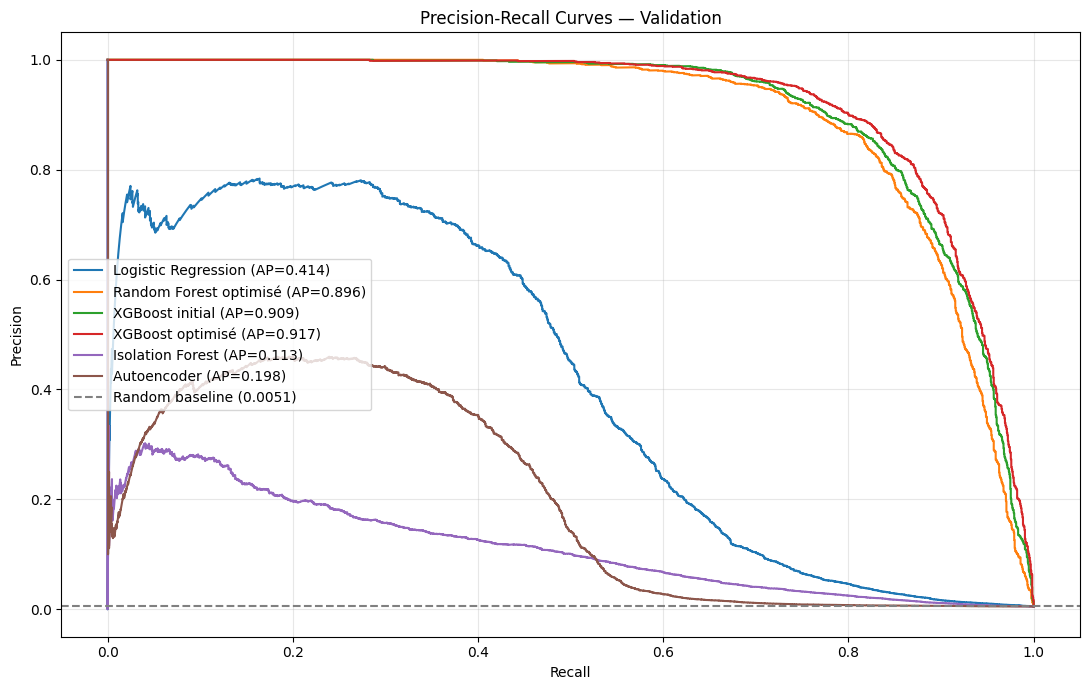

In [63]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt
import numpy as np

# Scores obtenus sur Validation
model_scores = {
    "Logistic Regression": scores_normal,
    "Random Forest optimisé": scores_rf_best,
    "XGBoost initial": scores_xgb_initial,
    "XGBoost optimisé": scores_xgb_best,
    "Isolation Forest": scores_if,
    "Autoencoder": scores_ae
}

plt.figure(figsize=(11, 7))

for name, scores in model_scores.items():

    precision, recall, _ = precision_recall_curve(
        y_val, scores
    )

    ap = average_precision_score(y_val, scores)

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP={ap:.3f})"
    )

# Référence aléatoire
baseline = y_val.mean()

plt.axhline(
    baseline,
    color="gray",
    linestyle="--",
    label=f"Random baseline ({baseline:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves — Validation")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [64]:
# Precision@k et Recall@k - Validation

budgets = [1000, 3000, 5000]

y_true = y_val.to_numpy()
total_frauds = y_true.sum()

ranking_results = []

for name, scores in model_scores.items():

    scores = np.asarray(scores)

    # Trier les transactions du score le plus élevé au plus faible
    order = np.argsort(-scores, kind="stable")

    for k in budgets:

        # Sélectionner les k transactions les plus suspectes
        top_k = order[:k]

        # Nombre de fraudes détectées
        detected_frauds = y_true[top_k].sum()

        precision_k = detected_frauds / k
        recall_k = detected_frauds / total_frauds

        ranking_results.append({
            "Modele": name,
            "Budget_k": k,
            "Fraudes_detectees": detected_frauds,
            "Precision@k": precision_k,
            "Recall@k": recall_k
        })

ranking_df = pd.DataFrame(ranking_results)

display(
    ranking_df.sort_values(
        ["Budget_k", "Precision@k"],
        ascending=[True, False]
    ).round(4)
)

,Modele,Budget_k,Fraudes_detectees,Precision@k,Recall@k
9,XGBoost optimisé,1000,996,0.9960,0.5239
6,XGBoost initial,1000,993,0.9930,0.5224
3,Random Forest optimisé,1000,991,0.9910,0.5213
0,Logistic Regression,1000,704,0.7040,0.3703
15,Autoencoder,1000,459,0.4590,0.2415
12,Isolation Forest,1000,253,0.2530,0.1331
10,XGBoost optimisé,3000,1763,0.5877,0.9274
7,XGBoost initial,3000,1756,0.5853,0.9237
4,Random Forest optimisé,3000,1732,0.5773,0.9111
1,Logistic Regression,3000,1035,0.3450,0.5445


In [65]:
# Simulation de budgets d'alertes quotidiens

budgets_daily = [10, 20, 30]

daily_results = []

y_true = y_val.to_numpy()
amounts = val_fe["amt"].to_numpy()

dates = pd.to_datetime(
    val_fe["trans_date_trans_time"]
).dt.date.to_numpy()

total_frauds = y_true.sum()

for name, scores in model_scores.items():

    df_eval = pd.DataFrame({
        "date": dates,
        "score": np.asarray(scores),
        "is_fraud": y_true,
        "amt": amounts
    })

    # Trier les transactions par risque décroissant
    # pour chaque journée
    df_sorted = df_eval.sort_values(
        ["date", "score"],
        ascending=[True, False],
        kind="stable"
    )

    for k in budgets_daily:

        # Sélectionner les k premières alertes de chaque jour
        selected = (
            df_sorted.groupby("date", sort=False)
            .head(k)
        )

        alerts = len(selected)

        detected = int(selected["is_fraud"].sum())

        precision = detected / alerts if alerts else 0
        recall = detected / total_frauds

        # Montant total des fraudes
        total_fraud_amount = df_eval.loc[
            df_eval["is_fraud"] == 1, "amt"
        ].sum()

        # Montant des fraudes détectées
        detected_amount = selected.loc[
            selected["is_fraud"] == 1, "amt"
        ].sum()

        missed_cost = (
            total_fraud_amount - detected_amount
        )

        alert_cost = alerts * 5

        total_cost = missed_cost + alert_cost

        daily_results.append({
            "Modele": name,
            "Alertes_par_jour": k,
            "Total_alertes": alerts,
            "Fraudes_detectees": detected,
            "Precision": precision,
            "Recall": recall,
            "Missed_Cost": missed_cost,
            "Alert_Cost": alert_cost,
            "Total_Cost": total_cost
        })

daily_budget_df = pd.DataFrame(daily_results)

display(
    daily_budget_df.sort_values(
        ["Alertes_par_jour", "Total_Cost"],
        ascending=[True, True]
    ).round(4)
)

,Modele,Alertes_par_jour,Total_alertes,Fraudes_detectees,Precision,Recall,Missed_Cost,Alert_Cost,Total_Cost
6,XGBoost initial,10,1410,1095,0.7766,0.5760,371171.60,7050,378221.60
3,Random Forest optimisé,10,1410,1086,0.7702,0.5713,373766.36,7050,380816.36
9,XGBoost optimisé,10,1410,1102,0.7816,0.5797,388305.36,7050,395355.36
0,Logistic Regression,10,1410,723,0.5128,0.3803,441265.09,7050,448315.09
15,Autoencoder,10,1410,524,0.3716,0.2756,521641.42,7050,528691.42
12,Isolation Forest,10,1410,320,0.2270,0.1683,707814.48,7050,714864.48
4,Random Forest optimisé,20,2820,1563,0.5543,0.8222,103057.85,14100,117157.85
7,XGBoost initial,20,2820,1570,0.5567,0.8259,120192.40,14100,134292.40
10,XGBoost optimisé,20,2820,1577,0.5592,0.8296,124778.30,14100,138878.30
1,Logistic Regression,20,2820,980,0.3475,0.5155,301605.23,14100,315705.23


In [66]:
# Optimisation du seuil avec budget quotidien

daily_budgets = [10, 20, 30]
COST_PER_ALERT = 5

supervised_scores = {
    "Random Forest optimisé": scores_rf_best,
    "XGBoost initial": scores_xgb_initial,
    "XGBoost optimisé": scores_xgb_best
}

y_true = y_val.to_numpy()
amounts = val_fe["amt"].to_numpy()

dates = pd.to_datetime(
    val_fe["trans_date_trans_time"]
).dt.date.to_numpy()

cost_without_model = amounts[y_true == 1].sum()

hybrid_results = []

for name, scores in supervised_scores.items():

    df_eval = pd.DataFrame({
        "date": dates,
        "score": np.asarray(scores),
        "is_fraud": y_true,
        "amt": amounts
    })

    # Classer les transactions par risque pour chaque jour
    df_sorted = df_eval.sort_values(
        ["date", "score"],
        ascending=[True, False],
        kind="stable"
    )

    for k in daily_budgets:

        # Transactions éligibles : top k par jour
        top_daily = (
            df_sorted.groupby("date", sort=False)
            .head(k)
            .sort_values("score", ascending=False,
                         kind="stable")
        )

        s = top_daily["score"].to_numpy()
        y = top_daily["is_fraud"].to_numpy()
        a = top_daily["amt"].to_numpy()

        # Montants frauduleux potentiellement évités
        recovered = np.where(y == 1, a, 0)

        cumulative_recovered = np.cumsum(recovered)
        cumulative_tp = np.cumsum(y == 1)

        n_alerts = np.arange(1, len(s) + 1)

        costs = (
            cost_without_model
            - cumulative_recovered
            + COST_PER_ALERT * n_alerts
        )

        # Seuils correspondant aux scores distincts
        candidates = np.flatnonzero(
            np.r_[s[:-1] != s[1:], True]
        )

        best_idx = candidates[np.argmin(costs[candidates])]

        # Comparer aussi à la politique sans alerte
        if cost_without_model <= costs[best_idx]:
            threshold = np.nextafter(s.max(), np.inf)
            alerts = 0
            tp = 0
            total_cost = cost_without_model
        else:
            threshold = s[best_idx]
            alerts = int(n_alerts[best_idx])
            tp = int(cumulative_tp[best_idx])
            total_cost = float(costs[best_idx])

        hybrid_results.append({
            "Modele": name,
            "Budget_jour": k,
            "Threshold": threshold,
            "Alertes": alerts,
            "Fraudes_detectees": tp,
            "Precision": tp / alerts if alerts else 0,
            "Recall": tp / y_true.sum(),
            "Total_Cost": total_cost
        })

hybrid_df = pd.DataFrame(hybrid_results)

display(
    hybrid_df.sort_values(
        ["Budget_jour", "Total_Cost"]
    ).round(4)
)

,Modele,Budget_jour,Threshold,Alertes,Fraudes_detectees,Precision,Recall,Total_Cost
3,XGBoost initial,10,0.0688,1361,1095,0.8046,0.5760,377976.60
0,Random Forest optimisé,10,0.1245,1327,1084,0.8169,0.5702,380568.61
6,XGBoost optimisé,10,0.0675,1340,1100,0.8209,0.5786,395025.97
1,Random Forest optimisé,20,0.0810,2344,1545,0.6591,0.8127,116746.12
4,XGBoost initial,20,0.0688,2314,1558,0.6733,0.8196,131991.69
7,XGBoost optimisé,20,0.0269,2574,1574,0.6115,0.8280,137898.53
2,Random Forest optimisé,30,0.0176,3918,1731,0.4418,0.9106,49099.74
5,XGBoost initial,30,0.0307,3333,1725,0.5176,0.9074,53482.43
8,XGBoost optimisé,30,0.0177,3498,1744,0.4986,0.9174,55923.18


In [67]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score
import pandas as pd

# Groupes de variables à supprimer
ablation_groups = {
    "Toutes les features": [],

    "Sans temporelles": [
        "hour_sin", "hour_cos",
        "day_of_week", "is_weekend"
    ],

    "Sans montant actuel": [
        "amt", "amount_ratio_30d"
    ],

    "Sans categorie": [
        "category"
    ],

    "Sans comportementales": [
        "time_since_last_tx",
        "has_previous_tx",
        "tx_count_1h",
        "tx_count_24h",
        "tx_count_30d",
        "avg_amount_30d",
        "amount_ratio_30d"
    ],

    "Sans distance": [
        "distance_km"
    ]
}

ablation_results = []

for name, removed in ablation_groups.items():

    selected = [
        col for col in X_train.columns
        if col not in removed
    ]

    num_cols = [
        col for col in selected
        if col != "category"
    ]

    cat_cols = [
        col for col in selected
        if col == "category"
    ]

    # Reconstruire le prétraitement
    transformers = [
        (
            "num",
            SimpleImputer(strategy="median"),
            num_cols
        )
    ]

    if cat_cols:
        transformers.append((
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            cat_cols
        ))

    preprocessing = ColumnTransformer(transformers)

    # Même modèle pour chaque expérience
    model = Pipeline([
        ("preprocessing", preprocessing),
        ("model", clone(
            xgb_initial.named_steps["model"]
        ))
    ])

    # Entraînement
    model.fit(X_train[selected], y_train)

    # Évaluation sur Validation
    scores = model.predict_proba(
        X_val[selected]
    )[:, 1]

    pr_auc = average_precision_score(y_val, scores)

    ablation_results.append({
        "Experience": name,
        "Nb_features": len(selected),
        "PR_AUC": pr_auc
    })

ablation_df = pd.DataFrame(ablation_results)

# Comparaison avec toutes les features
reference = ablation_df.loc[
    ablation_df["Experience"] == "Toutes les features",
    "PR_AUC"
].iloc[0]

ablation_df["Delta_PR_AUC"] = (
    ablation_df["PR_AUC"] - reference
)

display(
    ablation_df.sort_values(
        "PR_AUC", ascending=False
    ).round(4)
)

,Experience,Nb_features,PR_AUC,Delta_PR_AUC
5,Sans distance,14,0.9095,0.0008
0,Toutes les features,15,0.9087,0.0000
1,Sans temporelles,11,0.8479,-0.0608
4,Sans comportementales,8,0.8113,-0.0974
3,Sans categorie,14,0.7505,-0.1582
2,Sans montant actuel,13,0.4944,-0.4143


,Mois,Transactions,Fraudes,Taux_fraude,XGBoost initial,XGBoost optimise,Random Forest optimise
0,2020-04,53149,244,0.0046,0.9086,0.9257,0.8932
1,2020-05,74343,527,0.0071,0.9548,0.9608,0.9499
2,2020-06,87805,467,0.0053,0.8958,0.9036,0.8790
3,2020-07,85848,321,0.0037,0.8984,0.9034,0.8815
4,2020-08,69334,342,0.0049,0.8634,0.8745,0.8482


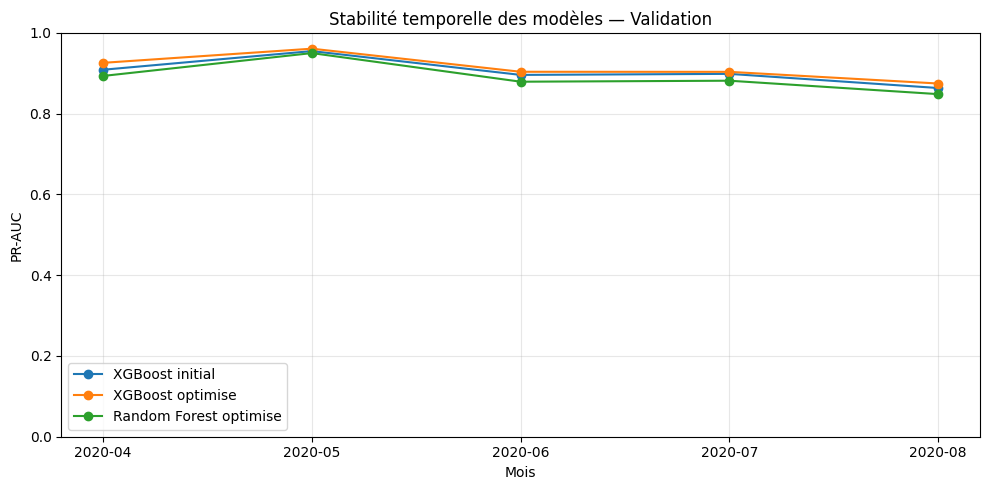

In [68]:
# Analyse de la stabilité temporelle sur Validation

from sklearn.metrics import average_precision_score, roc_auc_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

temporal_eval = pd.DataFrame({
    "date": pd.to_datetime(val_fe["trans_date_trans_time"]),
    "is_fraud": y_val.to_numpy(),
    "XGBoost initial": scores_xgb_initial,
    "XGBoost optimise": scores_xgb_best,
    "Random Forest optimise": scores_rf_best
})

temporal_eval["month"] = (
    temporal_eval["date"].dt.to_period("M").astype(str)
)

temporal_results = []

for month, group in temporal_eval.groupby("month", sort=True):

    y_month = group["is_fraud"]

    if y_month.nunique() < 2:
        continue

    result = {
        "Mois": month,
        "Transactions": len(group),
        "Fraudes": int(y_month.sum()),
        "Taux_fraude": y_month.mean()
    }

    for model in [
        "XGBoost initial",
        "XGBoost optimise",
        "Random Forest optimise"
    ]:
        result[model] = average_precision_score(
            y_month, group[model]
        )

    temporal_results.append(result)

temporal_df = pd.DataFrame(temporal_results)

display(temporal_df.round(4))

# Visualisation
plt.figure(figsize=(10, 5))

for model in [
    "XGBoost initial",
    "XGBoost optimise",
    "Random Forest optimise"
]:
    plt.plot(
        temporal_df["Mois"],
        temporal_df[model],
        marker="o",
        label=model
    )

plt.xlabel("Mois")
plt.ylabel("PR-AUC")
plt.title("Stabilité temporelle des modèles — Validation")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [69]:
# Comparaison à la référence aléatoire mensuelle

temporal_df["Baseline_AP"] = temporal_df["Taux_fraude"]

temporal_df["AP_Lift_XGB"] = (
    temporal_df["XGBoost optimise"]
    / temporal_df["Baseline_AP"]
)

display(
    temporal_df[[
        "Mois",
        "Fraudes",
        "Taux_fraude",
        "XGBoost optimise",
        "AP_Lift_XGB"
    ]].round(4)
)

,Mois,Fraudes,Taux_fraude,XGBoost optimise,AP_Lift_XGB
0,2020-04,244,0.0046,0.9257,201.6441
1,2020-05,527,0.0071,0.9608,135.5319
2,2020-06,467,0.0053,0.9036,169.8906
3,2020-07,321,0.0037,0.9034,241.6082
4,2020-08,342,0.0049,0.8745,177.2915


In [70]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.special import expit

# Échantillon de validation
rng = np.random.default_rng(42)

idx_alert = int(np.argmax(scores_xgb_best))

indices = rng.choice(
    len(X_val),
    size=min(1499, len(X_val)),
    replace=False
)

indices = np.unique(np.r_[indices, idx_alert])

X_shap = X_val.iloc[indices].copy()

# Pipeline XGBoost optimisé
preprocessor = best_xgb.named_steps["preprocessing"]
model = best_xgb.named_steps["model"]

# Prétraitement déjà entraîné
X_transformed = preprocessor.transform(X_shap)

if sparse.issparse(X_transformed):
    X_transformed = X_transformed.toarray()

feature_names = preprocessor.get_feature_names_out()

# Calcul SHAP
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_transformed)

phi = np.asarray(shap_values.values)

if phi.ndim == 3:
    phi = phi[:, :, 1]

base_values = np.asarray(shap_values.base_values)

if base_values.ndim == 0:
    base_values = np.full(len(X_shap), float(base_values))
elif base_values.ndim == 2:
    base_values = base_values[:, 1]

print("Transactions analysées :", len(X_shap))
print("Features après encodage :", len(feature_names))
print("Dimensions SHAP :", phi.shape)

Transactions analysées : 1500
Features après encodage : 28
Dimensions SHAP : (1500, 28)


,Mean_abs_SHAP
amt,2.3812
category,0.8015
hour_cos,0.7992
avg_amount_30d,0.4802
tx_count_30d,0.4322
time_since_last_tx,0.3970
city_pop,0.2728
hour_sin,0.2609
tx_count_24h,0.2597
amount_ratio_30d,0.2112


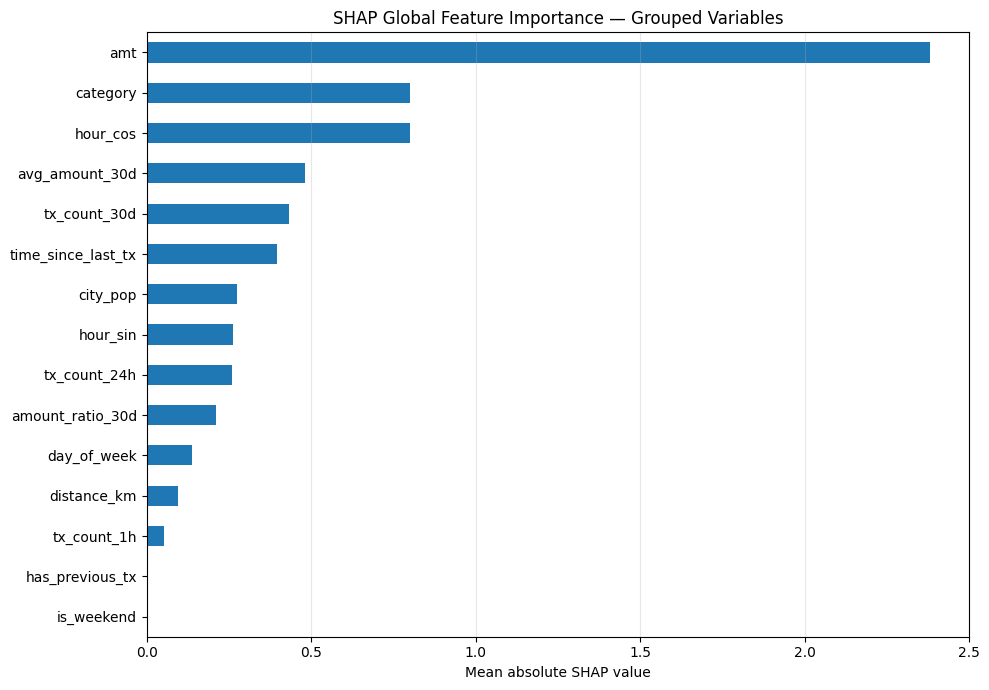

In [71]:
# Regrouper les contributions SHAP
grouped_features = X_val.columns.tolist()

phi_grouped = np.zeros(
    (len(X_shap), len(grouped_features))
)

feature_positions = {
    name: i
    for i, name in enumerate(grouped_features)
}

for j, encoded_name in enumerate(feature_names):

    if encoded_name.startswith("num__"):
        original_name = encoded_name.split("__", 1)[1]

    elif encoded_name.startswith("cat__category_"):
        original_name = "category"

    else:
        raise ValueError(
            f"Feature non reconnue : {encoded_name}"
        )

    phi_grouped[:, feature_positions[original_name]] += phi[:, j]

# Importance globale
importance = pd.Series(
    np.abs(phi_grouped).mean(axis=0),
    index=grouped_features
).sort_values(ascending=False)

display(
    importance.rename("Mean_abs_SHAP")
    .to_frame().round(4)
)

# Graphique
plt.figure(figsize=(10, 7))

importance.sort_values().plot.barh()

plt.xlabel("Mean absolute SHAP value")
plt.title("SHAP Global Feature Importance — Grouped Variables")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1437: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


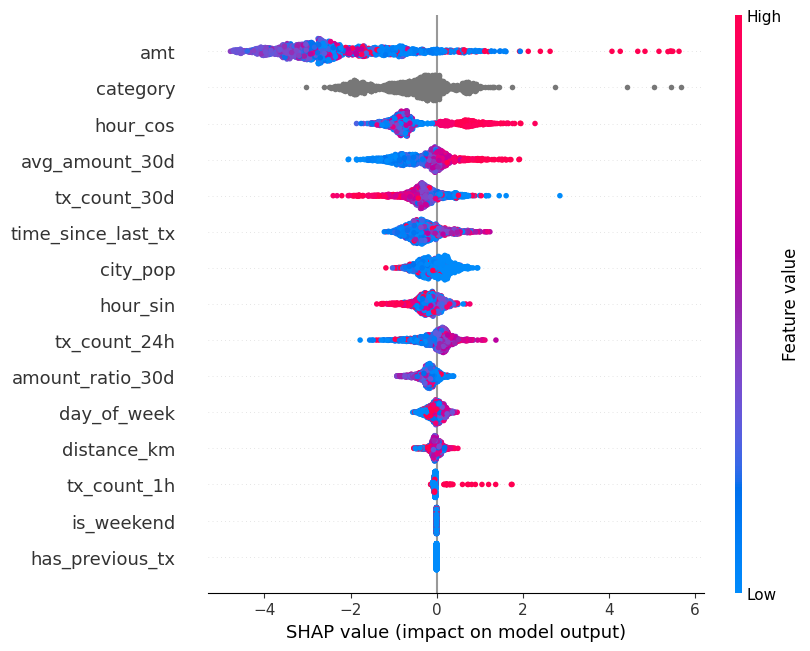

In [72]:
# Données pour la visualisation
plot_data = X_shap[grouped_features].copy()

# category est qualitative : pas d'échelle numérique artificielle
plot_data["category"] = np.nan

# Explanation avec les variables regroupées
grouped_explanation = shap.Explanation(
    values=phi_grouped,
    base_values=base_values,
    data=plot_data.to_numpy(dtype=float),
    feature_names=grouped_features
)

# Beeswarm
shap.plots.beeswarm(
    grouped_explanation,
    max_display=15,
    show=True
)

===== TRANSACTION ANALYSÉE =====
Score de fraude : 0.999984
Classe réelle : 1


,trans_date_trans_time,amt,category,is_fraud
51425,2020-04-29 23:58:29,297.4,grocery_pos,1


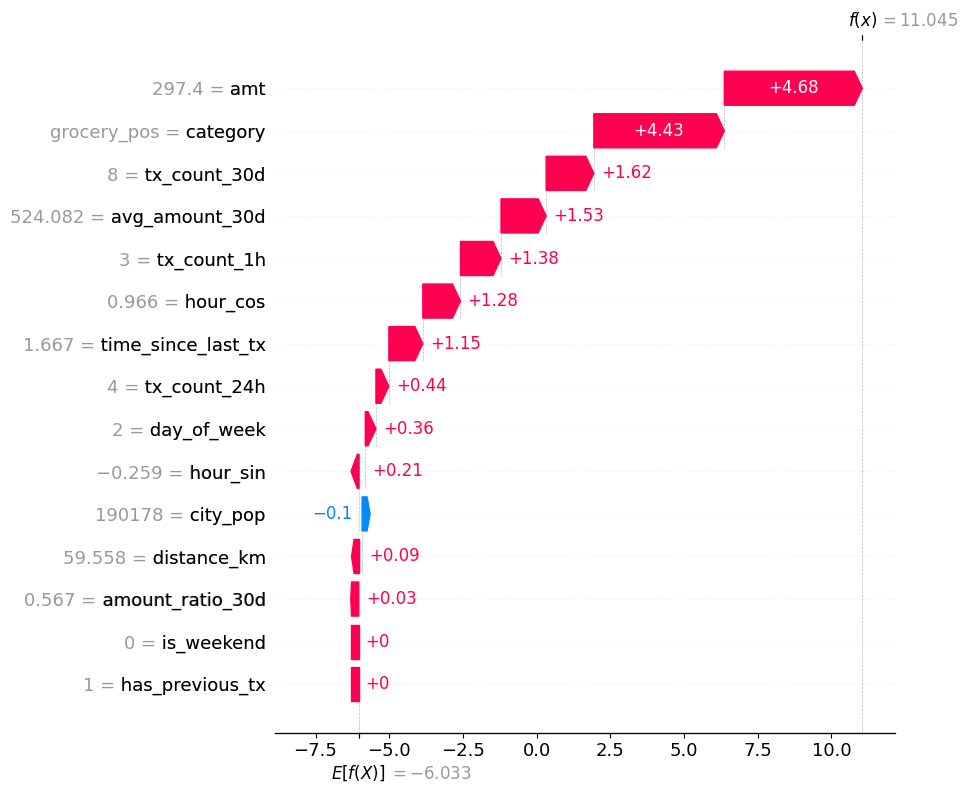

Probabilité reconstruite avec SHAP : 0.999984


In [73]:
# Transaction au score le plus élevé
local_position = int(np.where(indices == idx_alert)[0][0])

transaction = X_shap.iloc[local_position]

print("===== TRANSACTION ANALYSÉE =====")
print("Score de fraude :", round(float(scores_xgb_best[idx_alert]), 6))
print("Classe réelle :", int(y_val.iloc[idx_alert]))

display(
    val_fe.iloc[[idx_alert]][[
        "trans_date_trans_time",
        "amt",
        "category",
        "is_fraud"
    ]]
)

# Explication locale avec les variables originales
local_explanation = shap.Explanation(
    values=phi_grouped[local_position],
    base_values=float(base_values[local_position]),
    data=transaction[grouped_features].to_numpy(dtype=object),
    feature_names=grouped_features
)

shap.plots.waterfall(
    local_explanation,
    max_display=15,
    show=True
)

# Vérifier la cohérence avec le score du modèle
p_shap = expit(
    float(base_values[local_position])
    + phi_grouped[local_position].sum()
)

print("Probabilité reconstruite avec SHAP :", round(float(p_shap), 6))

In [74]:
# Contributions locales
local_shap_df = pd.DataFrame({
    "Motif": grouped_features,
    "Valeur": [
        transaction[col]
        for col in grouped_features
    ],
    "SHAP": phi_grouped[local_position]
})

# Principaux facteurs augmentant le score de fraude
top_motifs = (
    local_shap_df[local_shap_df["SHAP"] > 0]
    .sort_values("SHAP", ascending=False)
    .head(5)
)

print("===== PRINCIPAUX MOTIFS D'ALERTE =====")

display(top_motifs.round(4))

===== PRINCIPAUX MOTIFS D'ALERTE =====


,Motif,Valeur,SHAP
0,amt,297.4,4.6791
14,category,grocery_pos,4.4257
10,tx_count_30d,8,1.6183
11,avg_amount_30d,524.0825,1.5302
8,tx_count_1h,3,1.3752


In [76]:
# Analyse des erreurs — XGBoost optimisé

threshold = 0.0165

y_true = y_val.to_numpy()
scores = np.asarray(scores_xgb_best)

y_pred = (scores >= threshold).astype(int)

# Identifier les erreurs
fp_idx = np.where((y_true == 0) & (y_pred == 1))[0]
fn_idx = np.where((y_true == 1) & (y_pred == 0))[0]

print("Faux positifs :", len(fp_idx))
print("Faux négatifs :", len(fn_idx))

# Faux positif au score le plus élevé
fp_example = fp_idx[np.argmax(scores[fp_idx])]

# Fraude manquée avec le montant le plus élevé
fn_example = fn_idx[
    np.argmax(val_fe.iloc[fn_idx]["amt"].to_numpy())
]

examples = val_fe.iloc[
    [fp_example, fn_example]
][[
    "trans_date_trans_time",
    "amt",
    "category",
    "is_fraud"
]].copy()

examples["Score_fraude"] = scores[
    [fp_example, fn_example]
]

examples["Type_erreur"] = [
    "Faux positif",
    "Faux négatif"
]

display(examples.round(4))

Faux positifs : 2315
Faux négatifs : 84


,trans_date_trans_time,amt,category,is_fraud,Score_fraude,Type_erreur
91636,2020-05-18 03:48:26,269.18,grocery_pos,0,0.9952,Faux positif
64933,2020-05-05 19:45:59,1132.30,shopping_net,1,0.0068,Faux négatif


In [77]:
# Seuil optimal exact sur Validation
threshold = optimize_threshold(
    scores_xgb_best,
    y_val.to_numpy(),
    val_fe["amt"].to_numpy(),
    alert_cost=5
)["Threshold"]

scores = np.asarray(scores_xgb_best)
y_true = y_val.to_numpy()

y_pred = (scores >= threshold).astype(int)

fp_idx = np.where(
    (y_true == 0) & (y_pred == 1)
)[0]

fn_idx = np.where(
    (y_true == 1) & (y_pred == 0)
)[0]

# Faux positif avec le score le plus élevé
fp_example = fp_idx[np.argmax(scores[fp_idx])]

# Faux négatif avec le montant le plus élevé
fn_example = fn_idx[
    np.argmax(val_fe.iloc[fn_idx]["amt"].to_numpy())
]

error_indices = [fp_example, fn_example]

print("Seuil exact :", threshold)
print("Faux positifs :", len(fp_idx))
print("Faux négatifs :", len(fn_idx))

display(
    val_fe.iloc[error_indices][[
        "trans_date_trans_time",
        "amt",
        "category",
        "is_fraud"
    ]]
)

Seuil exact : 0.016453668
Faux positifs : 2321
Faux négatifs : 83


,trans_date_trans_time,amt,category,is_fraud
91636,2020-05-18 03:48:26,269.18,grocery_pos,0
64933,2020-05-05 19:45:59,1132.30,shopping_net,1



==== Faux positif ====
Score du modèle : 0.995219


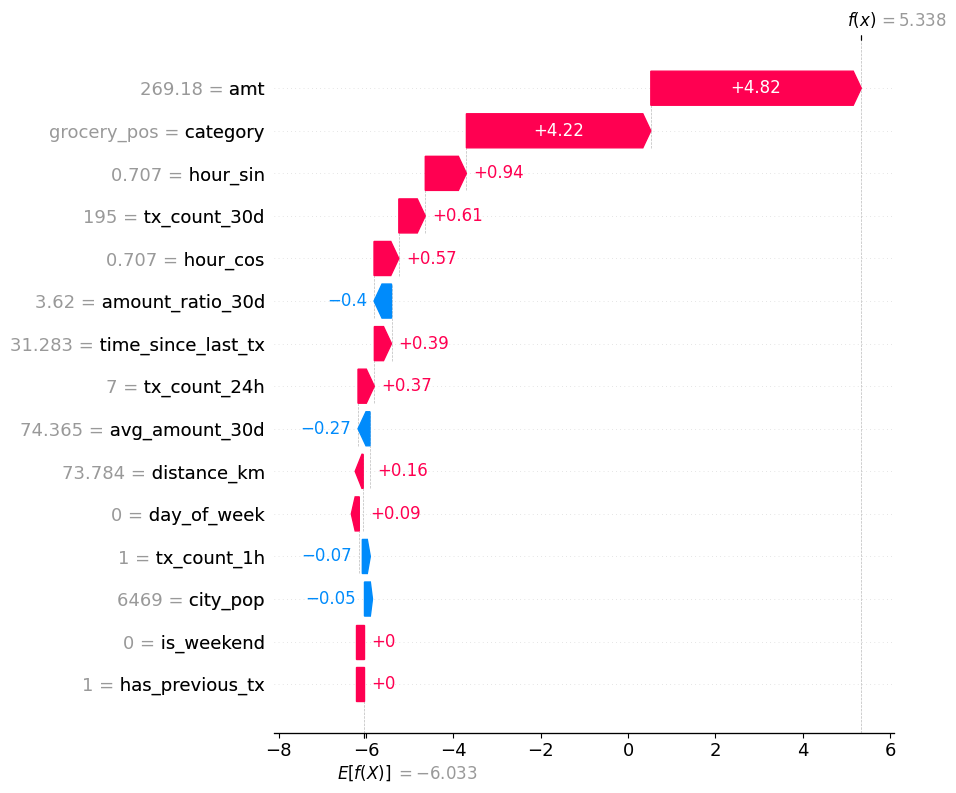


==== Faux négatif ====
Score du modèle : 0.006764


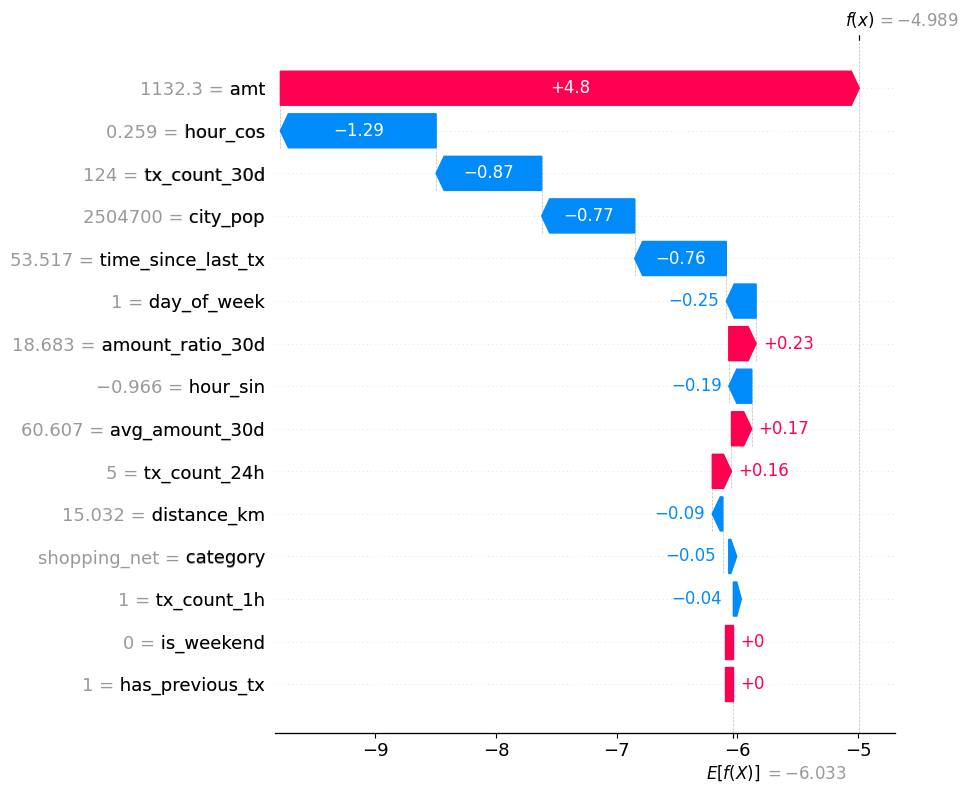

In [78]:
# Transactions à expliquer
X_errors = X_val.iloc[error_indices].copy()

preprocessor = best_xgb.named_steps["preprocessing"]
xgb_model = best_xgb.named_steps["model"]

# Prétraitement
X_errors_transformed = preprocessor.transform(X_errors)

if sparse.issparse(X_errors_transformed):
    X_errors_transformed = X_errors_transformed.toarray()

# SHAP
explainer_errors = shap.TreeExplainer(xgb_model)
shap_errors = explainer_errors(X_errors_transformed)

feature_names = preprocessor.get_feature_names_out()
original_features = X_train.columns.tolist()

# Regroupement des contributions
grouped_values = np.zeros(
    (len(X_errors), len(original_features))
)

for j, name in enumerate(feature_names):

    if name.startswith("cat__category_"):
        original_name = "category"
    else:
        original_name = name.split("__", 1)[-1]

    position = original_features.index(original_name)

    grouped_values[:, position] += shap_errors.values[:, j]

# Explications locales
for i, error_type in enumerate([
    "Faux positif",
    "Faux négatif"
]):

    explanation = shap.Explanation(
        values=grouped_values[i],
        base_values=float(np.asarray(
            shap_errors.base_values
        ).reshape(-1)[i]),
        data=X_errors.iloc[i][original_features].to_numpy(),
        feature_names=original_features
    )

    print("\n====", error_type, "====")
    print("Score du modèle :", round(scores[error_indices[i]], 6))

    shap.plots.waterfall(
        explanation,
        max_display=15,
        show=True
    )

In [79]:
for i, error_type in enumerate([
    "Faux positif",
    "Faux négatif"
]):

    motifs = pd.DataFrame({
        "Feature": original_features,
        "Valeur": X_errors.iloc[i][original_features].values,
        "SHAP": grouped_values[i]
    })

    if error_type == "Faux positif":
        # Facteurs qui augmentent la prédiction de fraude
        top = motifs.sort_values(
            "SHAP", ascending=False
        ).head(5)

    else:
        # Facteurs qui diminuent la prédiction de fraude
        top = motifs.sort_values(
            "SHAP", ascending=True
        ).head(5)

    print("\n====", error_type, "====")
    display(top.round(4))


==== Faux positif ====


,Feature,Valeur,SHAP
0,amt,269.18,4.8168
14,category,grocery_pos,4.2215
2,hour_sin,0.707107,0.9413
10,tx_count_30d,195,0.6056
3,hour_cos,0.707107,0.5677



==== Faux négatif ====


,Feature,Valeur,SHAP
3,hour_cos,0.258819,-1.2902
10,tx_count_30d,124,-0.8748
1,city_pop,2504700,-0.7709
6,time_since_last_tx,53.516667,-0.7591
4,day_of_week,1,-0.2470


In [80]:
# Analyse globale des erreurs de XGBoost optimisé

threshold = optimize_threshold(
    scores_xgb_best,
    y_val.to_numpy(),
    val_fe["amt"].to_numpy(),
    alert_cost=5
)["Threshold"]

error_df = pd.DataFrame({
    "is_fraud": y_val.to_numpy(),
    "score": scores_xgb_best,
    "amt": val_fe["amt"].to_numpy(),
    "category": val_fe["category"].to_numpy(),
    "hour": pd.to_datetime(
        val_fe["trans_date_trans_time"]
    ).dt.hour.to_numpy()
})

error_df["prediction"] = (
    error_df["score"] >= threshold
).astype(int)

# Séparer les erreurs
fp = error_df[
    (error_df["is_fraud"] == 0)
    & (error_df["prediction"] == 1)
]

fn = error_df[
    (error_df["is_fraud"] == 1)
    & (error_df["prediction"] == 0)
]

print("===== ANALYSE DES ERREURS =====")

print("Seuil exact :", threshold)
print("Faux positifs :", len(fp))
print("Faux négatifs :", len(fn))

print("Montant total des fraudes manquées :",
      round(fn["amt"].sum(), 2))

print("\nMontant moyen des fraudes manquées :",
      round(fn["amt"].mean(), 2))

print("\nTop 10 des fraudes manquées les plus coûteuses :")

display(
    fn.sort_values("amt", ascending=False)
    .head(10).round(4)
)

print("\nCatégories les plus fréquentes parmi les faux négatifs :")

display(
    fn["category"].value_counts().head(10)
)

print("\nCatégories les plus fréquentes parmi les faux positifs :")

display(
    fp["category"].value_counts().head(10)
)

===== ANALYSE DES ERREURS =====
Seuil exact : 0.016453668
Faux positifs : 2321
Faux négatifs : 83
Montant total des fraudes manquées : 13560.58

Montant moyen des fraudes manquées : 163.38

Top 10 des fraudes manquées les plus coûteuses :


,is_fraud,score,amt,category,hour,prediction
64933,1,0.0068,1132.30,shopping_net,19,0
208254,1,0.0079,1071.19,shopping_net,6,0
13357,1,0.0094,1056.24,shopping_net,12,0
332512,1,0.0135,927.37,shopping_pos,12,0
327900,1,0.0105,876.32,misc_net,7,0
353152,1,0.0064,874.71,shopping_pos,18,0
170231,1,0.0007,780.14,shopping_pos,18,0
175691,1,0.0028,742.74,misc_net,7,0
350829,1,0.0137,645.41,misc_pos,3,0
139370,1,0.0019,633.21,misc_net,23,0



Catégories les plus fréquentes parmi les faux négatifs :


category
kids_pets         14
food_dining       12
personal_care     12
travel            10
health_fitness     9
misc_pos           8
home               6
shopping_pos       4
shopping_net       3
misc_net           3
Name: count, dtype: int64


Catégories les plus fréquentes parmi les faux positifs :


category
shopping_net      331
misc_pos          301
shopping_pos      283
kids_pets         216
personal_care     213
misc_net          177
grocery_net       158
food_dining       156
travel            122
health_fitness    122
Name: count, dtype: int64

In [81]:
# Analyse des taux d'erreur par catégorie

threshold = optimize_threshold(
    scores_xgb_best,
    y_val.to_numpy(),
    val_fe["amt"].to_numpy(),
    alert_cost=5
)["Threshold"]

y = y_val.to_numpy()
pred = (np.asarray(scores_xgb_best) >= threshold)

errors_category = pd.DataFrame({
    "category": val_fe["category"].to_numpy(),
    "Fraudes": (y == 1).astype(int),
    "Normales": (y == 0).astype(int),
    "FP": ((y == 0) & pred).astype(int),
    "FN": ((y == 1) & ~pred).astype(int),
    "Montant_FN": np.where(
        (y == 1) & ~pred,
        val_fe["amt"].to_numpy(),
        0
    )
})

category_errors = errors_category.groupby("category").agg(
    Fraudes=("Fraudes", "sum"),
    Normales=("Normales", "sum"),
    FP=("FP", "sum"),
    FN=("FN", "sum"),
    Montant_FN=("Montant_FN", "sum")
).reset_index()

category_errors["Taux_FN_%"] = (
    100 * category_errors["FN"]
    / category_errors["Fraudes"].replace(0, np.nan)
)

category_errors["Taux_FP_%"] = (
    100 * category_errors["FP"]
    / category_errors["Normales"].replace(0, np.nan)
)

display(
    category_errors.sort_values(
        "Montant_FN", ascending=False
    ).round(2)
)

,category,Fraudes,Normales,FP,FN,Montant_FN,Taux_FN_%,Taux_FP_%
11,shopping_net,408,27625,331,3,3259.73,0.74,1.20
12,shopping_pos,219,33097,283,4,3209.21,1.83,0.86
8,misc_net,222,17965,177,3,2252.27,1.35,0.99
1,food_dining,48,26220,156,12,1479.68,25.00,0.59
6,home,64,34777,112,6,1401.07,9.38,0.32
9,misc_pos,72,22813,301,8,786.42,11.11,1.32
10,personal_care,65,25949,213,12,384.83,18.46,0.82
7,kids_pets,62,32450,216,14,264.44,22.58,0.67
4,grocery_pos,425,34666,37,1,241.45,0.24,0.11
5,health_fitness,55,24497,122,9,186.69,16.36,0.50


In [82]:
# Simulation instantanée avec budget quotidien

import numpy as np
import pandas as pd

BUDGET_DAILY = 30
COST_PER_ALERT = 5

models_online = {
    "XGBoost initial": scores_xgb_initial,
    "XGBoost optimisé": scores_xgb_best,
    "Random Forest optimisé": scores_rf_best
}

# Trier les transactions chronologiquement
timestamps = pd.to_datetime(
    val_fe["trans_date_trans_time"]
).to_numpy()

order = np.argsort(timestamps, kind="stable")

dates = pd.to_datetime(
    timestamps[order]
).normalize().to_numpy()

y = y_val.to_numpy()[order]
amounts = val_fe["amt"].to_numpy()[order]

# Identifiant numérique de chaque journée
day_id = np.cumsum(
    np.r_[True, dates[1:] != dates[:-1]]
) - 1

total_frauds = y.sum()
cost_without_model = amounts[y == 1].sum()


def simulate_online(scores, threshold, budget=30):

    # Transactions dont le score dépasse le seuil
    eligible = np.flatnonzero(scores >= threshold)

    if len(eligible) == 0:
        selected = np.array([], dtype=int)

    else:
        # Journée correspondant à chaque transaction éligible
        d = day_id[eligible]

        # Repérer le début de chaque nouvelle journée
        starts = np.maximum.accumulate(
            np.where(
                np.r_[True, d[1:] != d[:-1]],
                np.arange(len(eligible)),
                0
            )
        )

        # Rang chronologique des alertes dans chaque journée
        ranks = np.arange(len(eligible)) - starts

        # Accepter seulement les premières alertes disponibles
        selected = eligible[ranks < budget]

    alerts = len(selected)
    detected = int(y[selected].sum())

    recovered = amounts[selected][y[selected] == 1].sum()

    missed_cost = cost_without_model - recovered
    alert_cost = alerts * COST_PER_ALERT

    return {
        "Alertes": alerts,
        "Fraudes_detectees": detected,
        "Precision": detected / alerts if alerts else 0,
        "Recall": detected / total_frauds,
        "Missed_Cost": missed_cost,
        "Total_Cost": missed_cost + alert_cost,
        "Max_alertes_jour": (
            np.bincount(
                day_id[selected],
                minlength=day_id.max() + 1
            ).max()
            if alerts else 0
        )
    }


# Optimiser le seuil sur Validation
online_results = []

for name, original_scores in models_online.items():

    scores = np.asarray(original_scores)[order]

    # Seuils candidats adaptés à la distribution des scores
    thresholds = np.unique(
        np.r_[
            0.0,
            1.0,
            np.quantile(
                scores,
                np.linspace(0.90, 0.9999, 150)
            )
        ]
    )

    best = None

    for threshold in thresholds:

        result = simulate_online(
            scores,
            threshold,
            BUDGET_DAILY
        )

        if best is None or result["Total_Cost"] < best["Total_Cost"]:

            best = result.copy()
            best["Threshold"] = float(threshold)

    best["Modele"] = name
    online_results.append(best)


online_df = pd.DataFrame(online_results)

display(
    online_df.sort_values("Total_Cost").round(4)
)

assert (online_df["Max_alertes_jour"] <= BUDGET_DAILY).all()

,Alertes,Fraudes_detectees,Precision,Recall,Missed_Cost,Total_Cost,Max_alertes_jour,Threshold,Modele
2,1997,1581,0.7917,0.8317,74456.03,84441.03,30,0.2227,Random Forest optimisé
0,2226,1627,0.7309,0.8559,82779.63,93909.63,30,0.1442,XGBoost initial
1,1994,1620,0.8124,0.8522,86218.97,96188.97,30,0.1945,XGBoost optimisé


In [83]:
# Configuration retenue sur Validation

selected_model_name = "Random Forest optimisé"

selected_row = online_df.loc[
    online_df["Modele"] == selected_model_name
].iloc[0]

final_model = best_rf
final_threshold = float(selected_row["Threshold"])
final_daily_budget = 30
final_alert_cost = 5

print("===== CONFIGURATION RETENUE =====")
print("Modèle :", selected_model_name)
print("Seuil exact :", final_threshold)
print("Budget journalier :", final_daily_budget)
print("Coût par alerte :", final_alert_cost)

print("\nPerformances sur Validation :")
print("Alertes :", int(selected_row["Alertes"]))
print("Fraudes détectées :",
      int(selected_row["Fraudes_detectees"]))
print("Precision :", round(selected_row["Precision"], 4))
print("Recall :", round(selected_row["Recall"], 4))
print("Coût métier :", round(selected_row["Total_Cost"], 2))

===== CONFIGURATION RETENUE =====
Modèle : Random Forest optimisé
Seuil exact : 0.22266507475921693
Budget journalier : 30
Coût par alerte : 5

Performances sur Validation :
Alertes : 1997
Fraudes détectées : 1581
Precision : 0.7917
Recall : 0.8317
Coût métier : 84441.03


In [84]:
# Vérification indépendante des features historiques sur Validation

import numpy as np
import pandas as pd

# Sélectionner 50 transactions de Validation
sample_val = val_fe.sample(
    n=50,
    random_state=42
).copy()

# Historique disponible : Train et Validation uniquement
history_subset = history_df.loc[
    history_df["_split"].isin(["train", "val"])
    & history_df["cc_num"].isin(sample_val["cc_num"]),
    ["cc_num", "trans_date_trans_time", "amt"]
].copy()

# Préparer les historiques par carte
card_histories = {}

for card, group in history_subset.groupby("cc_num"):

    group = group.sort_values("trans_date_trans_time")

    times = pd.to_datetime(
        group["trans_date_trans_time"]
    ).to_numpy(dtype="datetime64[ns]")

    amounts = group["amt"].to_numpy(dtype=float)

    cumulative_amounts = np.r_[
        0.0, np.cumsum(amounts)
    ]

    card_histories[card] = (
        times,
        cumulative_amounts
    )

# Recalculer les features à partir du passé uniquement
errors = []

features_to_check = [
    "has_previous_tx",
    "time_since_last_tx",
    "tx_count_1h",
    "tx_count_24h",
    "tx_count_30d",
    "avg_amount_30d",
    "amount_ratio_30d"
]

for idx, row in sample_val.iterrows():

    times, cumulative = card_histories[row["cc_num"]]

    t = np.datetime64(
        row["trans_date_trans_time"], "ns"
    )

    # Transactions strictement antérieures à t
    p = np.searchsorted(times, t, side="left")

    # Début des fenêtres temporelles
    start_1h = np.searchsorted(
        times, t - np.timedelta64(1, "h"), side="left"
    )

    start_24h = np.searchsorted(
        times, t - np.timedelta64(24, "h"), side="left"
    )

    start_30d = np.searchsorted(
        times, t - np.timedelta64(30, "D"), side="left"
    )

    # Dernière transaction
    time_since = (
        (t - times[p - 1]) / np.timedelta64(1, "m")
        if p > 0 else np.nan
    )

    # Montant moyen sur les 30 jours précédents
    count_30d = p - start_30d

    avg_30d = (
        (cumulative[p] - cumulative[start_30d]) / count_30d
        if count_30d > 0 else np.nan
    )

    ratio_30d = (
        row["amt"] / avg_30d
        if pd.notna(avg_30d) and avg_30d > 0
        else np.nan
    )

    expected = {
        "has_previous_tx": int(p > 0),
        "time_since_last_tx": time_since,
        "tx_count_1h": p - start_1h,
        "tx_count_24h": p - start_24h,
        "tx_count_30d": count_30d,
        "avg_amount_30d": avg_30d,
        "amount_ratio_30d": ratio_30d
    }

    for feature in features_to_check:

        if not np.isclose(
            row[feature],
            expected[feature],
            rtol=1e-6,
            atol=1e-6,
            equal_nan=True
        ):
            errors.append({
                "Index": idx,
                "Feature": feature,
                "Notebook": row[feature],
                "Calcul_independant": expected[feature]
            })

print("===== AUDIT DU FEATURE ENGINEERING =====")
print("Transactions contrôlées :", len(sample_val))
print("Features contrôlées :", len(features_to_check))
print("Incohérences détectées :", len(errors))

if errors:
    display(pd.DataFrame(errors).head(20))
else:
    print("Toutes les features historiques vérifiées sont cohérentes.")

assert len(errors) == 0

===== AUDIT DU FEATURE ENGINEERING =====
Transactions contrôlées : 50
Features contrôlées : 7
Incohérences détectées : 0
Toutes les features historiques vérifiées sont cohérentes.


In [85]:
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    fbeta_score,
    matthews_corrcoef,
    confusion_matrix
)
import numpy as np
import pandas as pd

# Configuration figée sur Validation
model = final_model
threshold = final_threshold
daily_budget = final_daily_budget
cost_per_alert = final_alert_cost

# Scores sur Test (sans réentraînement)
scores_test = model.predict_proba(X_test)[:, 1]

# Préparer les transactions
test_eval = pd.DataFrame({
    "date": pd.to_datetime(
        test_fe["trans_date_trans_time"]
    ).to_numpy(),
    "score": scores_test,
    "is_fraud": y_test.to_numpy(),
    "amt": test_fe["amt"].to_numpy()
})

assert test_eval["date"].notna().all()
assert np.isfinite(test_eval["score"]).all()

# Ordre chronologique
test_eval = test_eval.sort_values(
    "date", kind="stable"
).reset_index(drop=True)

test_eval["jour"] = test_eval["date"].dt.normalize()

# Transactions dépassant le seuil
test_eval["eligible"] = (
    test_eval["score"] >= threshold
)

# Nombre de transactions éligibles déjà rencontrées
test_eval["rang_eligible"] = (
    test_eval.groupby("jour")["eligible"].cumsum()
)

# Déclencher une alerte seulement si budget disponible
test_eval["alerte"] = (
    test_eval["eligible"]
    & (test_eval["rang_eligible"] <= daily_budget)
)

# Valeurs réelles et prédictions
y_true = test_eval["is_fraud"].to_numpy()
y_pred = test_eval["alerte"].astype(int).to_numpy()

# Métriques
pr_auc = average_precision_score(
    y_true, test_eval["score"]
)

roc_auc = roc_auc_score(
    y_true, test_eval["score"]
)

precision = precision_score(
    y_true, y_pred, zero_division=0
)

recall = recall_score(
    y_true, y_pred, zero_division=0
)

f2 = fbeta_score(
    y_true, y_pred, beta=2, zero_division=0
)

mcc = matthews_corrcoef(y_true, y_pred)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

# Coût métier
missed = (y_true == 1) & (y_pred == 0)

missed_cost = test_eval.loc[
    missed, "amt"
].sum()

alert_cost = int(y_pred.sum()) * cost_per_alert

total_cost = missed_cost + alert_cost

cost_without_model = test_eval.loc[
    test_eval["is_fraud"] == 1, "amt"
].sum()

# Vérification du budget
max_daily_alerts = test_eval.groupby("jour")[
    "alerte"
].sum().max()

assert max_daily_alerts <= daily_budget

print("===== TEST FINAL FRAUDGUARD V2 =====")

print("PR-AUC :", round(pr_auc, 4))
print("ROC-AUC :", round(roc_auc, 4))
print("Precision :", round(precision, 4))
print("Recall :", round(recall, 4))
print("F2-score :", round(f2, 4))
print("MCC :", round(mcc, 4))

print("\nMatrice de confusion :")
print(cm)

print("\nAlertes :", int(y_pred.sum()))
print("Fraudes détectées :", int(cm[1, 1]))
print("Fraudes manquées :", int(cm[1, 0]))

print("\nMontant des fraudes manquées :",
      round(missed_cost, 2))

print("Coût d'analyse :", round(alert_cost, 2))
print("Coût métier total :", round(total_cost, 2))
print("Coût sans modèle :", round(cost_without_model, 2))

print("\nMaximum d'alertes par jour :", max_daily_alerts)
print("Seuil utilisé :", threshold)

===== TEST FINAL FRAUDGUARD V2 =====
PR-AUC : 0.8853
ROC-AUC : 0.9952
Precision : 0.7281
Recall : 0.8458
F2-score : 0.8193
MCC : 0.7839

Matrice de confusion :
[[368704    426]
 [   208   1141]]

Alertes : 1567
Fraudes détectées : 1141
Fraudes manquées : 208

Montant des fraudes manquées : 49990.76
Coût d'analyse : 7835
Coût métier total : 57825.76
Coût sans modèle : 733911.72

Maximum d'alertes par jour : 30
Seuil utilisé : 0.22266507475921693


In [86]:
import joblib
import json
import shutil
import numpy as np
from pathlib import Path

# Dossier de sauvegarde
output_dir = Path("/kaggle/working/FraudGuard_V2_Model")
output_dir.mkdir(parents=True, exist_ok=True)

model_path = output_dir / "random_forest_pipeline_v2.joblib"

# Sauvegarder le pipeline entraîné
joblib.dump(final_model, model_path, compress=3)

# Configuration opérationnelle
config_v2 = {
    "project": "FraudGuard AI",
    "version": "2.0",
    "model": "RandomForestClassifier",
    "features": X_train.columns.tolist(),
    "threshold": float(final_threshold),
    "daily_alert_budget": int(final_daily_budget),
    "cost_per_alert": float(final_alert_cost),
    "alert_strategy": "online_threshold_daily_budget",
    "pr_auc_test": float(pr_auc),
    "roc_auc_test": float(roc_auc),
    "precision_test": float(precision),
    "recall_test": float(recall),
    "f2_test": float(f2),
    "mcc_test": float(mcc)
}

config_path = output_dir / "config.json"

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(config_v2, f, indent=4, ensure_ascii=False)

# Vérifier le rechargement
loaded_model = joblib.load(model_path)

sample = X_test.iloc[:100].copy()

scores_before = final_model.predict_proba(sample)[:, 1]
scores_after = loaded_model.predict_proba(sample)[:, 1]

np.testing.assert_allclose(
    scores_before,
    scores_after,
    rtol=1e-10,
    atol=1e-10
)

print("Modèle sauvegardé :", model_path)
print("Configuration :", config_path)
print("Vérification du rechargement : OK")

# Créer une archive ZIP
archive = shutil.make_archive(
    "/kaggle/working/FraudGuard_V2_Model",
    "zip",
    output_dir
)

print("Archive créée :", archive)

Modèle sauvegardé : /kaggle/working/FraudGuard_V2_Model/random_forest_pipeline_v2.joblib
Configuration : /kaggle/working/FraudGuard_V2_Model/config.json
Vérification du rechargement : OK
Archive créée : /kaggle/working/FraudGuard_V2_Model.zip
